# **¿El crecimiento económico mejora la expectativa de vida? Predicción de la esperanza de vida con datos del World Bank**


## __Datos del autor__

**Autor:** Juan Díaz  
**Nombre del archivo:** AnalisisCalidadDeVidaGDPWorldBank_Final_Diaz.__.ipynb

---

## **Abstract**

Este proyecto analiza si el crecimiento económico de los países se relaciona con mejores expectativa de vida.

Para ello, se utilizan datos públicos del **World Bank** sobre cuatro indicadores principales:

- **GDP per capita**
- **Esperanza de vida**
- **Población**
- **Alfabetización**


La variable principal de calidad de vida es la `life_expectancy`, como variables explicativas se utilizan indicadores económicos, demográficos y temporales, como el PBI per cápita, la población total y el año.

El objetivo principal es responder si los países con mayor crecimiento económico tienden a presentar mejores niveles de esperanza de vida, y si esta relación puede utilizarse para construir un modelo predictivo.

El análisis está orientado a una audiencia interesada en desarrollo económico, políticas públicas y análisis social basado en datos.

El proyecto incluye:

- Limpieza y transformación de datos.
- Análisis exploratorio de datos.
- Visualizaciones para obtener insights.
- Modelos de Machine Learning para predecir la esperanza de vida a partir de variables económicas, demográficas y temporales.

Desde el punto de vista de Machine Learning, el problema se formula como una regresión, ya que se busca predecir una variable numérica continua: la esperanza de vida.


## **Motivación**

El GDP per capita suele utilizarse como una medida del desarrollo económico de un país. Sin embargo,
> * un mayor nivel económico
> * → _no siempre garantiza mejores condiciones de vida_.

Por eso, este análisis busca evaluar:  
>- hasta qué punto el crecimiento económico se refleja en un indicador de bienestar como la esperanza de vida.


## **Audiencia**

Este análisis puede ser útil para:

- organismos públicos
- equipos de planificación social
- analistas económicos
- organizaciones internacionales
- personas interesadas en desarrollo, bienestar y políticas públicas.


## **Preguntas**

- ¿Los países con mayor gdp_per_capita tienden a tener mayor life_expectancy?
- ¿La relación entre crecimiento económico y esperanza de vida es lineal?
- ¿Existen países con GDP medio o bajo que logran una esperanza de vida relativamente alta?
- ¿Existen países con GDP alto que no alcanzan una esperanza de vida alta?
- ¿Se puede predecir la esperanza de vida usando variables económicas, demográficas y temporales?

## **Hipótesis**
- Los países con mayor GDP per capita tienden a tener mayor esperanza de vida.
- El GDP per capita se relaciona positivamente con la esperanza de vida, pero no la explica por completo.
- Existen países que se alejan de la tendencia general, lo que sugiere que otros factores sociales, institucionales o sanitarios también influyen.
- Un modelo de Machine Learning puede predecir la esperanza de vida con un error aceptable usando gdp_per_capita, population y year.

# Parte I - Cargar Datos
1. Cargar los CSV.
2. Revisar estructura.
3. Crear dataset principal.
---



In [ ]:
# 1. Sistema operativo
import os

# 2. datos y gráficos
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 3. Machine Learning
# Modelos y Selección de datos
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    RandomizedSearchCV,
    cross_validate,
    train_test_split,
)
# Métricas de evaluación
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 1 Cargar CSV

In [ ]:
# Links
GDP_URL = "https://drive.google.com/uc?id=12AafvF3Se05t9YPUDwV1l6e8pigmdnus&export=download"
LIFE_URL = "https://drive.google.com/uc?id=1GM-mJIgVnzmrNbaf47cLjD2Jj1IchVhn&export=download"
POPULATION_URL = "https://drive.google.com/uc?id=1dtS7tPJJRNWAVcky16rgLAB_rdSoEsVL&export=download"
LITERACY_URL = "https://drive.google.com/uc?id=1GNoS6jdvrrKAMu_AyNIQYzTLJPZiMj1Z&export=download"

# Cargar archivos
gdp = pd.read_csv(GDP_URL, skiprows=4)
life_expectancy = pd.read_csv(LIFE_URL, skiprows=4)
population = pd.read_csv(POPULATION_URL, skiprows=4)
literacy = pd.read_csv(LITERACY_URL, skiprows=4)

# Verificar tamaños
print("GDP:", gdp.shape)
print("Life expectancy:", life_expectancy.shape)
print("Population:", population.shape)
print("Literacy:", literacy.shape)

GDP: (266, 71)
Life expectancy: (266, 71)
Population: (266, 71)
Literacy: (266, 71)


## 2 Revisar columnas.

### 2.1. Revisar gdp.

In [ ]:
gdp.head(2)

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,37524.914920,39287.059713,38543.907294,28854.597300,35104.786804,41758.895757,46574.357420,50649.301523,NaN,NaN
1,Africa Eastern and Southern,AFE,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3837.726375,3723.216423,3801.413183,3708.094649,4028.376504,4369.191056,4501.601101,4635.788224,NaN,NaN


In [ ]:
# Revisar estructura del dataset de GDP

print("GDP")
print("Filas y columnas:", gdp.shape)
print("Primeras columnas:")
print(gdp.columns[:10])
print("Últimas columnas:")
print(gdp.columns[-5:])

GDP
Filas y columnas: (266, 71)
Primeras columnas:
Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1960', '1961', '1962', '1963', '1964', '1965'],
      dtype='object')
Últimas columnas:
Index(['2022', '2023', '2024', '2025', 'Unnamed: 70'], dtype='object')


#### Revisión del dataset de GDP

El dataset de **GDP per capita** contiene **266 filas** y **71 columnas**.

Las primeras columnas son de información descriptiva del país y del indicador:

- `Country Name`
- `Country Code`
- `Indicator Name`
- `Indicator Code`

Luego aparecen columnas por año, comenzando en **1960** y llegando hasta **2025**.

También se observa una columna llamada `Unnamed: 70`.  
Es una columna vacía común en archivo CSV. Antes de eliminarla, se revisará su contenido para confirmar si tiene datos relevantes o si puede descartarse.

---

#### ► Las columnas `Indicator Name` e `Indicator Code`

Las columnas `Indicator Name` e `Indicator Code`
- contienen información descriptiva del indicador.
- Se conservan solo como referencia inicial y luego se eliminan durante la limpieza del dataset.

### 2.2. Revisar life_expectancy, population,literacy .

In [ ]:
# Revisar estructura de columnas de cada DataFrame

datasets = {
    "GDP": gdp,
    "Life expectancy": life_expectancy,
    "Population": population,
    "Literacy": literacy
}

for name, df in datasets.items():
    print(f"\n{name}") # salto de línea
    print("-" * 40) # línea separadora de 40 guiones.
    print("Shape:", df.shape)
    print("Primeras columnas:")
    print(df.columns[:8].tolist())
    print("Últimas columnas:")
    print(df.columns[-5:].tolist())


GDP
----------------------------------------
Shape: (266, 71)
Primeras columnas:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963']
Últimas columnas:
['2022', '2023', '2024', '2025', 'Unnamed: 70']

Life expectancy
----------------------------------------
Shape: (266, 71)
Primeras columnas:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963']
Últimas columnas:
['2022', '2023', '2024', '2025', 'Unnamed: 70']

Population
----------------------------------------
Shape: (266, 71)
Primeras columnas:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963']
Últimas columnas:
['2022', '2023', '2024', '2025', 'Unnamed: 70']

Literacy
----------------------------------------
Shape: (266, 71)
Primeras columnas:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963']
Últimas columnas:
['2022', '2023', '2024', '20

### Revisión inicial de la estructura de los datasets

Los cuatro datasets tienen una estructura similar:

- **GDP:** 266 filas y 71 columnas.
- **Life expectancy:** 266 filas y 71 columnas.
- **Population:** 266 filas y 71 columnas.
- **Literacy:** 266 filas y 71 columnas.

Los cuatro DataFrames tienen columnas:
- `Country Name`
- `Country Code`
- `Indicator Name`
- `Indicator Code`

Luego aparecen columnas por año, desde **1960** hasta **2025**.

Todos los datasets tienen una columna final llamada `Unnamed: 70`.

Las columnas `Indicator Name` e `Indicator Code`
- sirven para identificar qué indicador contiene cada archivo.
- permiten confirmar si el dataset corresponde a GDP per capita, esperanza de vida, población o alfabetización.
- estas columnas no se usarán en el análisis ni en los modelos, porque son columnas descriptivas y no contienen valores que cambien por país o año.
- Después de verificar los indicadores, podrán eliminarse durante la limpieza.

---
Ahora revisamos las primeras filas para confirmar que los datos cargaron bien.

- No mostramos todas las columnas porque hay muchos años.
- Mostramos solo columnas clave y algunos años recientes.


### 2.3. Revisar primeras Filas


In [ ]:
# una lista manual
cols_revision = [
    "Country Name",
    "Country Code",
    "Indicator Name",
    "Indicator Code",
    "2019",
    "2020",
    "2021",
    "2022",
    "2023"
]

datasets = {
    "GDP": gdp,
    "Life expectancy": life_expectancy,
    "Population": population,
    "Literacy": literacy
}

for name, df in datasets.items():
    print(f"\n{name}")
    display(df[cols_revision].head())


GDP


,Country Name,Country Code,Indicator Name,Indicator Code,2019,2020,2021,2022,2023
0,Aruba,ABW,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,38543.907294,28854.597300,35104.786804,41758.895757,46574.357420
1,Africa Eastern and Southern,AFE,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,3801.413183,3708.094649,4028.376504,4369.191056,4501.601101
2,Afghanistan,AFG,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,2583.485332,2561.981761,2144.166570,2122.995815,2201.722907
3,Africa Western and Central,AFW,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,5484.249418,5414.042540,5690.967743,6220.122875,6520.280313
4,Angola,AGO,"GDP per capita, PPP (current international $)",NY.GDP.PCAP.PP.CD,8572.878956,7827.428043,8862.281333,9588.241295,9753.600468



Life expectancy


,Country Name,Country Code,Indicator Name,Indicator Code,2019,2020,2021,2022,2023
0,Aruba,ABW,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,76.019000,75.406000,73.655000,76.226000,76.353000
1,Africa Eastern and Southern,AFE,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,63.857261,63.766484,62.979999,64.487152,65.146228
2,Afghanistan,AFG,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,62.941000,61.454000,60.417000,65.617000,66.035000
3,Africa Western and Central,AFW,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,57.149956,57.364736,57.362736,57.987850,58.855740
4,Angola,AGO,"Life expectancy at birth, total (years)",SP.DYN.LE00.IN,63.051000,63.116000,62.958000,64.246000,64.617000



Population


,Country Name,Country Code,Indicator Name,Indicator Code,2019,2020,2021,2022,2023
0,Aruba,ABW,"Population, total",SP.POP.TOTL,109203.0,108587.0,107700.0,107310.0,107359.0
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,675950189.0,694446100.0,713090928.0,731821393.0,750491370.0
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,463365429.0,474569351.0,485920997.0,497387180.0,509398589.0
4,Angola,AGO,"Population, total",SP.POP.TOTL,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0



Literacy


,Country Name,Country Code,Indicator Name,Indicator Code,2019,2020,2021,2022,2023
0,Aruba,ABW,"Literacy rate, adult total (% of people ages 1...",SE.ADT.LITR.ZS,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Literacy rate, adult total (% of people ages 1...",SE.ADT.LITR.ZS,72.800003,72.980003,72.720001,73.059998,73.370003
2,Afghanistan,AFG,"Literacy rate, adult total (% of people ages 1...",SE.ADT.LITR.ZS,NaN,36.014965,37.270000,NaN,NaN
3,Africa Western and Central,AFW,"Literacy rate, adult total (% of people ages 1...",SE.ADT.LITR.ZS,60.139999,60.250000,60.509998,60.779999,61.029999
4,Angola,AGO,"Literacy rate, adult total (% of people ages 1...",SE.ADT.LITR.ZS,NaN,NaN,NaN,NaN,68.180000


#### Resultado de revisión de primeras Filas

Esto nos permite ver:

- si las filas son países/regiones,
- si el indicador corresponde al archivo
- si los años tienen valores
- si hay nulos visibles en años recientes

### 2.4. Confirmar indicadores
- Antes de transformar los datos, verificamos el nombre y código del indicador de cada archivo.
- Esto confirma que cada DataFrame contiene la variable esperada y evita errores al unir datasets con indicadores equivocados.

In [ ]:
# Revisar si Indicator Name e Indicator Code son constantes en cada dataset

for name, df in datasets.items():
    print(f"\n{name}")
    print("-" * 40)

    print("Indicator Name únicos:")
    print(df["Indicator Name"].unique())

    print("Indicator Code únicos:")
    print(df["Indicator Code"].unique())


GDP
----------------------------------------
Indicator Name únicos:
['GDP per capita, PPP (current international $)']
Indicator Code únicos:
['NY.GDP.PCAP.PP.CD']

Life expectancy
----------------------------------------
Indicator Name únicos:
['Life expectancy at birth, total (years)']
Indicator Code únicos:
['SP.DYN.LE00.IN']

Population
----------------------------------------
Indicator Name únicos:
['Population, total']
Indicator Code únicos:
['SP.POP.TOTL']

Literacy
----------------------------------------
Indicator Name únicos:
['Literacy rate, adult total (% of people ages 15 and above)']
Indicator Code únicos:
['SE.ADT.LITR.ZS']


#### Resultado de indicadores

Se verificó el nombre y código del indicador de cada archivo cargado.

- `gdp`: GDP per capita.
- `life_expectancy`: esperanza de vida.
- `population`: población total.
- `literacy`: alfabetización adulta.

## 3 Crear dataset principal

Transformar archivos raw para construir un dataset.

- Los archivos raw vienen en formato ancho
- cada año aparece como una columna.

Ejemplo:

`Country Name | Country Code | 1960 | 1961 | 1962 | ...`

Para analizar, se unen los indicadores usando un formato largo:

`country_name | country_code | year | value`

Entonces
- se crearán 4 DataFrames con esta estructura,
- uno por cada indicador:

- `gdp_long`
- `life_expectancy_long`
- `population_long`
- `literacy_long`

En cada uno, la columna `value` representa el valor numérico de ese indicador.
- es el valor numérico que estaba dentro de la columna del año de cada indicador.


Finalmente, se unen los DataFrames en un solo dataset.

---

### Justificación

Se necesita que cada fila represente una unidad de análisis:

`país + año`

Con esta estructura se pueden:
- comparar indicadores,
- crear visualizaciones y
- preparar los datos para ML.

---
## Parte II. Pasos

1. Transformar cada dataset a formato largo.
2. Crear un DataFrame largo por cada indicador.
3. Renombrar la columna `value` con el nombre real del indicador.
4. Revisar que cada DataFrame largo tenga la estructura correcta.
5. Unir los DataFrames usando `country_code` y `year`.
6. Crear el dataset maestro `worldbank_master`.
7. Revisar filas, columnas y primeras observaciones del dataset maestro.
8. Guardar el dataset maestro en `data/processed/`.

### 3.1 Transformar cada dataset a formato largo.

Los archivos originales del World Bank tienen un año por columna.
- `Country Name | Country Code | 1960 | 1961 | 1962 | ...`


Vamos a transformar cada archivo raw en un dataframe con la forma:
- `country_name | country_code | year | value`

---
- Usamos una función para transformar un dataset.
- Todavía no transforma nada permanente hasta que se llame a la función.


In [ ]:
# Función para transformar los dataset de formato ancho a formato largo
def transformar_a_formato_largo(df):

    # Selecciona las columnas que son años: 1960, 1961, 1962... n.
    year_cols = [col for col in df.columns if col.isdigit()]

    # Convierte las columnas de años en filas
    # Mantiene Country Name y Country Code como identificadores
    df_long = df.melt(
        id_vars=["Country Name", "Country Code"],
        value_vars=year_cols,
        var_name="year",
        value_name="value"
    )

    # Renombra columnas para usar nombres más limpios y consistentes
    df_long = df_long.rename(columns={
        "Country Name": "country_name",
        "Country Code": "country_code"
    })

    # Convierte la columna year de texto a número entero
    df_long["year"] = df_long["year"].astype(int)

    # Devuelve el DataFrame transformado
    return df_long

In [ ]:
callable(transformar_a_formato_largo)

True

In [ ]:
df_long_prueba = transformar_a_formato_largo(gdp)

df_long_prueba.shape, df_long_prueba.columns.tolist()

((17556, 4), ['country_name', 'country_code', 'year', 'value'])

### 3.2 Crear un DataFrame largo por cada indicador.


In [ ]:
# Transforma el dataset de GDP a formato largo
gdp_long = transformar_a_formato_largo(gdp)

# Transforma el dataset de esperanza de vida a formato largo
life_expectancy_long = transformar_a_formato_largo(life_expectancy)

# Transforma el dataset de población a formato largo
population_long = transformar_a_formato_largo(population)

# Transforma el dataset de alfabetización a formato largo
literacy_long = transformar_a_formato_largo(literacy)

In [ ]:
print("GDP long:", gdp_long.shape)
print("Life expectancy long:", life_expectancy_long.shape)
print("Population long:", population_long.shape)
print("Literacy long:", literacy_long.shape)

GDP long: (17556, 4)
Life expectancy long: (17556, 4)
Population long: (17556, 4)
Literacy long: (17556, 4)


In [ ]:
# Revisar dimensiones y columnas de los DataFrames transformados

long_datasets = {
    "GDP long": gdp_long,
    "Life expectancy long": life_expectancy_long,
    "Population long": population_long,
    "Literacy long": literacy_long
}

for name, df in long_datasets.items():
    print(f"\n{name}")
    print("-" * 40)
    print("Shape:", df.shape)
    print("Columnas:", df.columns.tolist())


GDP long
----------------------------------------
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'value']

Life expectancy long
----------------------------------------
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'value']

Population long
----------------------------------------
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'value']

Literacy long
----------------------------------------
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'value']


In [ ]:
# Revisar los 4 DataFrames ya transformados a formato largo

long_datasets = {
    "GDP long": gdp_long,
    "Life expectancy long": life_expectancy_long,
    "Population long": population_long,
    "Literacy long": literacy_long
}

for name, df in long_datasets.items():
    print(f"\n{name}")
    print("-" * 40)
    print("Shape:", df.shape)
    print("Columnas:", df.columns.tolist())
    display(df.head())


GDP long
----------------------------------------
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'value']


,country_name,country_code,year,value
0,Aruba,ABW,1960,NaN
1,Africa Eastern and Southern,AFE,1960,NaN
2,Afghanistan,AFG,1960,NaN
3,Africa Western and Central,AFW,1960,NaN
4,Angola,AGO,1960,NaN



Life expectancy long
----------------------------------------
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'value']


,country_name,country_code,year,value
0,Aruba,ABW,1960,64.049000
1,Africa Eastern and Southern,AFE,1960,44.169658
2,Afghanistan,AFG,1960,32.799000
3,Africa Western and Central,AFW,1960,37.779636
4,Angola,AGO,1960,37.933000



Population long
----------------------------------------
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'value']


,country_name,country_code,year,value
0,Aruba,ABW,1960,54922.0
1,Africa Eastern and Southern,AFE,1960,130075728.0
2,Afghanistan,AFG,1960,9035043.0
3,Africa Western and Central,AFW,1960,97630925.0
4,Angola,AGO,1960,5231654.0



Literacy long
----------------------------------------
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'value']


,country_name,country_code,year,value
0,Aruba,ABW,1960,NaN
1,Africa Eastern and Southern,AFE,1960,NaN
2,Afghanistan,AFG,1960,NaN
3,Africa Western and Central,AFW,1960,NaN
4,Angola,AGO,1960,NaN


### 3.3  Renombrar la columna value con el nombre real del indicador.


In [ ]:
gdp_long = gdp_long.rename(columns={"value": "gdp_per_capita"})
life_expectancy_long = life_expectancy_long.rename(columns={"value": "life_expectancy"})
population_long = population_long.rename(columns={"value": "population"})
literacy_long = literacy_long.rename(columns={"value": "literacy_rate"})

In [ ]:
gdp_long.head()

,country_name,country_code,year,gdp_per_capita
0,Aruba,ABW,1960,NaN
1,Africa Eastern and Southern,AFE,1960,NaN
2,Afghanistan,AFG,1960,NaN
3,Africa Western and Central,AFW,1960,NaN
4,Angola,AGO,1960,NaN


In [ ]:
# Verificar columnas después del renombrado

print("GDP:", gdp_long.columns.tolist())
print("Life expectancy:", life_expectancy_long.columns.tolist())
print("Population:", population_long.columns.tolist())
print("Literacy:", literacy_long.columns.tolist())

GDP: ['country_name', 'country_code', 'year', 'gdp_per_capita']
Life expectancy: ['country_name', 'country_code', 'year', 'life_expectancy']
Population: ['country_name', 'country_code', 'year', 'population']
Literacy: ['country_name', 'country_code', 'year', 'literacy_rate']


### 3.4 Revisar que cada DataFrame largo tenga la estructura correcta
Después de renombrar la columna `value`, revisamos que cada DataFrame tenga:.

- `country_name`
- `country_code`
- `year`
- una columna con el indicador correspondiente

Esta revisión confirma que los datos ya están listos para ser unidos.


In [ ]:
# Revisar columnas y primeras filas de cada DataFrame largo

long_datasets = {
    "GDP": gdp_long,
    "Life expectancy": life_expectancy_long,
    "Population": population_long,
    "Literacy": literacy_long
}

for name, df in long_datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Columnas:", df.columns.tolist())
    display(df.head())


GDP
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'gdp_per_capita']


,country_name,country_code,year,gdp_per_capita
0,Aruba,ABW,1960,NaN
1,Africa Eastern and Southern,AFE,1960,NaN
2,Afghanistan,AFG,1960,NaN
3,Africa Western and Central,AFW,1960,NaN
4,Angola,AGO,1960,NaN



Life expectancy
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'life_expectancy']


,country_name,country_code,year,life_expectancy
0,Aruba,ABW,1960,64.049000
1,Africa Eastern and Southern,AFE,1960,44.169658
2,Afghanistan,AFG,1960,32.799000
3,Africa Western and Central,AFW,1960,37.779636
4,Angola,AGO,1960,37.933000



Population
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'population']


,country_name,country_code,year,population
0,Aruba,ABW,1960,54922.0
1,Africa Eastern and Southern,AFE,1960,130075728.0
2,Afghanistan,AFG,1960,9035043.0
3,Africa Western and Central,AFW,1960,97630925.0
4,Angola,AGO,1960,5231654.0



Literacy
Shape: (17556, 4)
Columnas: ['country_name', 'country_code', 'year', 'literacy_rate']


,country_name,country_code,year,literacy_rate
0,Aruba,ABW,1960,NaN
1,Africa Eastern and Southern,AFE,1960,NaN
2,Afghanistan,AFG,1960,NaN
3,Africa Western and Central,AFW,1960,NaN
4,Angola,AGO,1960,NaN


### 3.5  Unir los DataFrames usando country_code y year.

Unir los indicadores en un solo dataset maestro.

Usamos `country_code` y `year` como claves de unión, porque juntos indican de qué país y de qué año es cada fila.

El resultado será una tabla donde cada fila contiene los indicadores para un país en un año específico.

Ejemplo:

| country_name | country_code | year | gdp_per_capita | life_expectancy | population | literacy_rate |
|---|---|---:|---:|---:|---:|---:|
| Argentina | ARG | 2019 | 23000 | 76.7 | 44938712 | 99.0 |
| Argentina | ARG | 2020 | 21500 | 75.9 | 45376763 | 99.1 |
| Brazil | BRA | 2019 | 15500 | 75.3 | 211782878 | 93.2 |
| Brazil | BRA | 2020 | 14800 | 74.0 | 213196304 | 93.3 |

En esta estructura, `BRA + 2019` permite unir el GDP, la esperanza de vida, la población y la alfabetización de Brasil para ese año.


In [ ]:
# Unir los DataFrames largos en un dataset
worldbank_master = gdp_long.merge(
    life_expectancy_long,
    on=["country_name", "country_code", "year"],
    how="outer"
)

worldbank_master = worldbank_master.merge(
    population_long,
    on=["country_name", "country_code", "year"],
    how="outer"
)

worldbank_master = worldbank_master.merge(
    literacy_long,
    on=["country_name", "country_code", "year"],
    how="outer"
)

worldbank_master.head()

,country_name,country_code,year,gdp_per_capita,life_expectancy,population,literacy_rate
0,Afghanistan,AFG,1960,NaN,32.799,9035043.0,NaN
1,Afghanistan,AFG,1961,NaN,33.291,9214083.0,NaN
2,Afghanistan,AFG,1962,NaN,33.757,9404406.0,NaN
3,Afghanistan,AFG,1963,NaN,34.201,9604487.0,NaN
4,Afghanistan,AFG,1964,NaN,34.673,9814318.0,NaN


### 3.6 Validar el dataset maestro

Después de unir los indicadores, revisamos la estructura del dataset creado.

Queremos confirmar:

- cuántas filas y columnas tiene
- si las columnas esperadas están presentes
- si cada combinación de `country_code` y `year` aparece una sola vez
- cuántos valores faltantes tiene cada indicador

Esta revisión nos dice si la unión funcion y qué problemas en los datos debemos trabajar después.

In [ ]:
# Validar estructura general del dataset principal
print("Shape:", worldbank_master.shape)

print("\nColumnas:")
print(worldbank_master.columns.tolist())

print("\nDuplicados por country_code + year:")
print(worldbank_master.duplicated(subset=["country_code", "year"]).sum())

print("\nValores faltantes por columna:")
print(worldbank_master.isna().sum())

Shape: (17556, 7)

Columnas:
['country_name', 'country_code', 'year', 'gdp_per_capita', 'life_expectancy', 'population', 'literacy_rate']

Duplicados por country_code + year:
0

Valores faltantes por columna:
country_name           0
country_code           0
year                   0
gdp_per_capita      9045
life_expectancy      365
population           361
literacy_rate      14713
dtype: int64


#### Interpretación de validación del dataset

El dataset fue creado correctamente.

- Filas: `17,556`
- Columnas: `7`

Columnas disponibles:

- `country_name`
- `country_code`
- `year`
- `gdp_per_capita`
- `life_expectancy`
- `population`
- `literacy_rate`

---

1. No hay duplicados por `country_code + year`. Esto confirma que cada país-año aparece una sola vez en el dataset.

2. Las columnas principales de identificación (`country_name`, `country_code`, `year`) están completas.

3. La variable `life_expectancy` tiene pocos valores faltantes, por eso puede funcionar bien como variable objetivo del modelo.

4. La variable `population` también está casi completa.

5. `gdp_per_capita` tiene bastantes valores faltantes, especialmente en años antiguos.

6. `literacy_rate` tiene muchos valores faltantes, por lo que no debe usarse como variable central.

### 3.7 Revisar datos por año

Revisar cuántos datos disponibles por `año` para cada `indicador`.

Esto nos ayuda a identificar qué años tienen mejor cobertura y cuáles pueden generar problemas por valores faltantes.

In [ ]:
# Revisar cantidad de valores disponibles por año en cada indicador

coverage_by_year = worldbank_master.groupby("year")[
    ["gdp_per_capita", "life_expectancy", "population", "literacy_rate"]
].count()

coverage_by_year.tail(15)

,gdp_per_capita,life_expectancy,population,literacy_rate
year,,,,
2011,249,265,265,90
2012,247,265,265,81
2013,248,265,265,70
2014,247,265,265,83
2015,247,265,265,85
2016,246,265,265,83
2017,247,265,265,83
2018,247,265,265,88
2019,247,265,265,95


#### Interpretación de cobertura por año

Los datos actuales pueden usarse, pero tienen limitaciones.


Para el objetivo de analizar si el `gdp_per_capita` se relaciona con la `life_expectancy`, los datos son adecuados
- Los indicadores `life_expectancy` y `population` tienen cobertura casi completa entre 2011 y 2024.

- gdp_per_capita` también tiene buena cobertura en años recientes, aunque no está completo para todos los países o regiones.

- `literacy_rate` tiene cobertura mucho menor. Su mejor año reciente es 2019, con 95 registros disponibles.

- El año 2025 no tiene datos disponibles, por lo que debe excluirse del análisis.

---

- `life_expectancy` → Buena cobertura. Puede usarse como variable objetivo del modelo.
- `population` → Buena cobertura. Puede usarse como variable de contexto.
- `gdp_per_capita` → Buena cobertura solo en años recientes. Puede usarse como variable económica.
- `literacy_rate` → Cobertura débil. Tiene muchos valores faltantes.

---

#### **Decisión inicial**

Se analizará:

- relación entre GDP per capita y esperanza de vida,
- evolución temporal de GDP,
- evolución temporal de esperanza de vida,
- comparación entre países,
- casos donde el GDP no se traduce claramente en mayor calidad de vida.

Para el análisis principal conviene trabajar con años recientes hasta 2024, excluyendo 2025.

- La variable `literacy_rate` tiene muchos valores faltantes
- Por eso, no se usará. En caso de incluirse, será solo como análisis complementario.

---

#### Posobilidad para aumentar el alcance

Se evaluará agregar variables sociales adicionales:

- `gini_index`: desigualdad.
- `secondary_enrollment`: escolarización secundaria.

Estas variables permitirían analizar si la riqueza económica se traduce en bienestar.


### 3.8 Guardar el dataset

Después de crear y validar `worldbank_master`, guardamos el dataset en la carpeta `data/processed/`.

Este archivo se usará para:

- análisis exploratorio,
- visualizaciones,
- preparación del dataset para Machine Learning,
- futuras versiones del proyecto.

In [ ]:
# Crear carpeta temporal en Colab llamada processed
PROCESSED_DIR = "/content/data/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Guardar dataset
worldbank_master_path = f"{PROCESSED_DIR}/worldbank_master.csv"

worldbank_master.to_csv(worldbank_master_path, index=False)

# Confirmar guardado
print("Dataset maestro guardado en:")
print(worldbank_master_path)

print("Shape guardado:", worldbank_master.shape)

Dataset maestro guardado en:
/content/data/processed/worldbank_master.csv
Shape guardado: (17556, 7)


---

# Parte II - Análisis Exploratorio de Datos (EDA)

- En esta etapa usaremos el dataset creado en la Parte I.

- El objetivo es entender la estructura, calidad y comportamiento de los datos antes de construir el modelo de ML.

- Primero revisaremos filas, columnas, tipos de datos, años disponibles y valores faltantes. Luego analizaremos distribuciones y relaciones entre variables.

## 1 Preparar el dataset para EDA

Como seguimos trabajando en el mismo notebook, el dataset principal ya existe en memoria con el nombre `worldbank_master`.

Para el análisis exploratorio, creamos una copia llamada `df`. Esto evita modificar el dataset  original.


In [ ]:
df = worldbank_master.copy()
df.head()

,country_name,country_code,year,gdp_per_capita,life_expectancy,population,literacy_rate
0,Afghanistan,AFG,1960,NaN,32.799,9035043.0,NaN
1,Afghanistan,AFG,1961,NaN,33.291,9214083.0,NaN
2,Afghanistan,AFG,1962,NaN,33.757,9404406.0,NaN
3,Afghanistan,AFG,1963,NaN,34.201,9604487.0,NaN
4,Afghanistan,AFG,1964,NaN,34.673,9814318.0,NaN


## 2 Revisar estructura general del dataset
Queremos confirmar:

- cantidad de filas
- cantidad de columnas
- nombres de columnas
- tipos de datos

Esto nos permite verificar si el dataset está listo para análisis o si necesita ajustes antes de graficar.

In [ ]:
# Revisar estructura del dataset

print("Filas y columnas:", df.shape)

print("\nColumnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)

Filas y columnas: (17556, 7)

Columnas:
['country_name', 'country_code', 'year', 'gdp_per_capita', 'life_expectancy', 'population', 'literacy_rate']

Tipos de datos:
country_name        object
country_code        object
year                 int64
gdp_per_capita     float64
life_expectancy    float64
population         float64
literacy_rate      float64
dtype: object


## 3 Revisión general
En este paso revisamos la estructura general del dataset antes de filtrar.

Primero veremos:
- tipos de datos
- rango de años
- países/regiones

Luego vamos a revisar
- cuántos datos disponibles hay en cada año
- decidir qué período usar en el análisis

In [ ]:
# Revisión general del dataset

print("Filas y columnas:", df.shape)

print("\nTipos de datos:")
print(df.dtypes)

print("\nRango de años:")
print("Año mínimo:", df["year"].min())
print("Año máximo:", df["year"].max())
print("Cantidad de años:", df["year"].nunique())

print("\nCantidad de países/regiones:")
print(df["country_code"].nunique())

print("\nPrimeros países/regiones:")
print(df["country_name"].drop_duplicates().head(15).tolist())

Filas y columnas: (17556, 7)

Tipos de datos:
country_name        object
country_code        object
year                 int64
gdp_per_capita     float64
life_expectancy    float64
population         float64
literacy_rate      float64
dtype: object

Rango de años:
Año mínimo: 1960
Año máximo: 2025
Cantidad de años: 66

Cantidad de países/regiones:
266

Primeros países/regiones:
['Afghanistan', 'Africa Eastern and Southern', 'Africa Western and Central', 'Albania', 'Algeria', 'American Samoa', 'Andorra', 'Angola', 'Antigua and Barbuda', 'Arab World', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria']


In [ ]:
# Revisar cobertura por año

coverage_by_year = df.groupby("year")[
    ["gdp_per_capita", "life_expectancy", "population", "literacy_rate"]
].count()

coverage_by_year.tail(25)

,gdp_per_capita,life_expectancy,population,literacy_rate
year,,,,
2001,242,265,265,67
2002,243,265,265,57
2003,243,265,265,52
2004,243,265,265,57
2005,243,265,265,59
2006,244,265,265,67
2007,245,265,265,68
2008,248,265,265,71
2009,249,265,265,68


### Resultado de revisión general y cobertura temporal

El dataset tiene
- `17,556` filas  
- `7` columnas.

Columnas disponibles:

- `country_name`
- `country_code`
- `year`
- `gdp_per_capita`
- `life_expectancy`
- `population`
- `literacy_rate`

Los tipos de datos son adecuados para esta etapa:

| Columna | Tipo de dato | Interpretación |
|---|---|---|
| `country_name` | object | Nombre del país o región |
| `country_code` | object | Código del país o región |
| `year` | int64 | Año |
| `gdp_per_capita` | float64 | Variable numérica |
| `life_expectancy` | float64 | Variable numérica |
| `population` | float64 | Variable numérica |
| `literacy_rate` | float64 | Variable numérica |

### Rango

El rango completo del dataset va de `1960` a `2025`.

También se identifican `266` países o regiones. Esto indica que el dataset contiene países individuales y también agregados regionales como:

- `Africa Eastern and Southern`
- `Africa Western and Central`
- `Arab World`

Estos agregados deberán revisarse más adelante si el análisis se quiere limitar solo a países.

### Cobertura por año

La cobertura confirma lo que vimos en la parte I.
Entre `2001` y `2024`, las variables principales tienen buena cobertura:

| Variable | Observación |
|---|---|
| `gdp_per_capita` | Buena cobertura desde 2001 hasta 2024 |
| `life_expectancy` | Cobertura casi completa |
| `population` | Cobertura casi completa |
| `literacy_rate` | Cobertura baja e irregular |

El año `2025` no tiene datos disponibles en ninguna variable, por lo que debe excluirse.

---
#### **Decisión inicial**

> Para el análisis principal, se trabajará con el período `2001–2024`.

> Se analizará la relación entre `gdp_per_capita`, `life_expectancy` y `population`.

> La variable `literacy_rate` no será central porque tiene baja cobertura. Se usará solo como análisis complementario si aporta valor.

#### **Tratamiento de años anteriores a 2001**

> Los años anteriores a `2001` no se eliminan del dataset maestro.

> Se conservan en `worldbank_master`, pero no se usarán en el análisis principal porque tienen menor cobertura para algunas variables.

> Si más adelante se requiere una revisión histórica simple, podrán usarse con variables que tengan mejor cobertura, como `life_expectancy` y `population`.

## 4 Crear dataset para el EDA principal

A partir del dataset maestro, creamos una versión filtrada para el análisis exploratorio.

Se usará el período `2001–2024` porque tiene buena cobertura para:

- `gdp_per_capita`
- `life_expectancy`
- `population`

El año `2025` se excluye porque no tiene datos disponibles.


In [ ]:
# Crear dataset filtrado para el EDA

df_eda = df[(df["year"] >= 2001) & (df["year"] <= 2024)].copy()

print("Filas y columnas:", df_eda.shape)
print("Año mínimo:", df_eda["year"].min())
print("Año máximo:", df_eda["year"].max())
print("Países/regiones:", df_eda["country_code"].nunique())

df_eda.head()

Filas y columnas: (6384, 7)
Año mínimo: 2001
Año máximo: 2024
Países/regiones: 266


,country_name,country_code,year,gdp_per_capita,life_expectancy,population,literacy_rate
41,Afghanistan,AFG,2001,747.688045,55.511,20284307.0,NaN
42,Afghanistan,AFG,2002,926.507941,56.225,21378117.0,NaN
43,Afghanistan,AFG,2003,966.962032,57.171,22733049.0,NaN
44,Afghanistan,AFG,2004,971.633503,57.810,23560654.0,NaN
45,Afghanistan,AFG,2005,1076.087353,58.247,24404567.0,NaN


## 5 Revisar valores faltantes en el dataset de EDA

Después de filtrar el período `2001–2024`, revisamos los valores faltantes.

Esto permite saber qué variables pueden usarse y cuáles necesitan mayor análisis.

In [ ]:
# Revisar valores faltantes en df_eda

missing_values = df_eda.isna().sum().sort_values(ascending=False)

missing_percent = (df_eda.isna().mean() * 100).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "missing_values": missing_values,
    "missing_percent": missing_percent
})

missing_summary

,missing_values,missing_percent
literacy_rate,4588,71.867168
gdp_per_capita,488,7.644110
life_expectancy,24,0.375940
population,24,0.375940
year,0,0.000000
country_name,0,0.000000
country_code,0,0.000000


#### Resultado de valores faltantes en `df_eda`

El dataset filtrado para el período `2001–2024` tiene `6,384` filas.

La revisión de valores faltantes muestra lo siguiente:

| Variable | Valores faltantes | Porcentaje faltante |
|---|---:|---:|
| `literacy_rate` | 4,588 | 71.87% |
| `gdp_per_capita` | 488 | 7.64% |
| `life_expectancy` | 24 | 0.38% |
| `population` | 24 | 0.38% |
| `year` | 0 | 0.00% |
| `country_name` | 0 | 0.00% |
| `country_code` | 0 | 0.00% |

#### Interpretación y decisión

> La variable `literacy_rate` tiene demasiados valores faltantes. Confirmamos no usarla como variable principal para el EDA ni para el modelo de ML.

> Las variables `life_expectancy` y `population` tienen muy pocos valores faltantes.

> La variable `gdp_per_capita` tiene algunos valores faltantes, pero su cobertura es aceptable para el análisis principal.

Para el análisis principal se usarán:

- `gdp_per_capita`
- `life_expectancy`
- `population`
- `year`

La variable `literacy_rate` se mantendrá en el dataset sin usarla.

## 6 Estadísticas descriptivas

En este paso se revisan las estadísticas básicas de las variables numéricas.

El objetivo es entender
- la escala de cada variable,
- detectar valores extremos
- confirmar qué variables tienen suficiente información para el análisis.

In [ ]:
# Estadísticas descriptivas de variables numéricas en df_eda

df_eda[
    [
        "gdp_per_capita",
        "life_expectancy",
        "population",
        "literacy_rate"
    ]
].describe()

,gdp_per_capita,life_expectancy,population,literacy_rate
count,5896.000000,6360.000000,6.360000e+03,1796.000000
mean,19386.795700,70.777204,2.905055e+08,80.755410
std,21881.033828,8.476372,9.063918e+08,16.766924
min,403.983197,14.665000,9.586000e+03,14.380000
25%,4234.776541,65.477750,1.493272e+06,67.572502
50%,11250.708294,72.163543,9.798470e+06,86.465000
75%,27286.928915,77.106171,6.012358e+07,94.849998
max,180939.439450,86.497000,8.141809e+09,100.000000


### Interpretación de estadística descriptiva

| Variable          | Observación                                                                                                                                |
| ----------------- | ------------------------------------------------------------------------------------------------------------------------------------------ |
| `gdp_per_capita`  | Tiene 5,896 valores disponibles. Presenta mucha diferencia entre el mínimo y el máximo, lo que indica valores extremos y alta dispersión.  |
| `life_expectancy` | Tiene 6,360 valores disponibles. Su rango va de 14.67 a 86.50 años. Es una variable con buena cobertura para el análisis.                  |
| `population` | Tiene 6,360 valores disponibles. Presenta valores muy grandes, lo esperado porque incluye países y regiones con poblaciones muy distintas. |
| `literacy_rate`   | Tiene solo 1,796 valores disponibles. Su cobertura es baja frente a las demás |

- life_expectancy y population tienen buena cobertura dentro del período 2001–2024.

- gdp_per_capita tiene cobertura aceptable, pero muestra alta dispersión. Esto puede afectar los gráficos y el modelo.
- Podría usarse escala logarítmica más adelante.


## 7 Crear dataset limpio para el EDA principal

En este paso se crea `df_eda_main`, una versión limpia del dataset para el análisis principal.

Se seleccionan solo las variables que tienen cobertura suficiente:

- `country_name`
- `country_code`
- `year`
- `gdp_per_capita`
- `life_expectancy`
- `population`

La variable `literacy_rate` queda fuera porque tiene demasiados valores nulos o faltantes.

Luego se eliminan las filas con valores nulos usando `.dropna()`.

Este dataset se usará para el EDA principal, visualizaciones y como base inicial para elmodelo de ML.


In [ ]:
df_eda_main = df_eda[
    [
        "country_name",
        "country_code",
        "year",
        "gdp_per_capita",
        "life_expectancy",
        "population"
    ]
].dropna()

print("Filas y columnas:", df_eda_main.shape)
print("Año mínimo:", df_eda_main["year"].min())
print("Año máximo:", df_eda_main["year"].max())
print("Países/regiones:", df_eda_main["country_code"].nunique())

df_eda_main.head()

Filas y columnas: (5896, 6)
Año mínimo: 2001
Año máximo: 2024
Países/regiones: 251


,country_name,country_code,year,gdp_per_capita,life_expectancy,population
41,Afghanistan,AFG,2001,747.688045,55.511,20284307.0
42,Afghanistan,AFG,2002,926.507941,56.225,21378117.0
43,Afghanistan,AFG,2003,966.962032,57.171,22733049.0
44,Afghanistan,AFG,2004,971.633503,57.810,23560654.0
45,Afghanistan,AFG,2005,1076.087353,58.247,24404567.0


### Resultado de creación de `df_eda_main`

Se creó el dataset para el EDA principal que contiene:

> - `5,896` filas
> - `6` columnas
> - período: `2001–2024`
> - `251` países/regiones

Columnas incluidas:

> - `country_name`
> - `country_code`
> - `year`
> - `gdp_per_capita`
> - `life_expectancy`
> - `population`

### Acciones
- Se eliminaron las filas con valores nulos en las variables principales usando `.dropna()`.

#### Interpretación
Con el dataset `df_eda_main` se puede
- analizar la relación entre nivel económico, esperanza de vida y población.

- También puede servir como base inicial para un modelo de Machine Learning simple, usando `life_expectancy` como variable objetivo.

## 8 Revisar países y agregados regionales

El dataset incluye países individuales y también agregados regionales o económicos.

Ejemplos de agregados:

- `Arab World`
- `Africa Eastern and Southern`
- `High income`
- `World`

Estos registros pueden distorsionar el análisis porque no representan países individuales.

Antes de crear gráficos o preparar datos para ML, se revisan estos registros para decidir cuáles excluir.

### En el código
> La lista de palabras clave se construyó a partir de nombres observados en `country_name` que corresponden a regiones, grupos de ingreso o agregados económicos. Es una revisión parcial.

In [ ]:
# Revisar posibles regiones o agregados dentro del dataset

possible_aggregates = df_eda_main[
    df_eda_main["country_name"].str.contains(
        "World|income|Africa|Arab|Europe|Euro|OECD|IDA|IBRD|Latin America|Caribbean|East Asia|South Asia|Sub-Saharan|Middle East",
        case=False,
        na=False
    )
]["country_name"].drop_duplicates().sort_values()

possible_aggregates.tolist()

['Africa Eastern and Southern',
 'Africa Western and Central',
 'Arab World',
 'Caribbean small states',
 'Central African Republic',
 'Central Europe and the Baltics',
 'East Asia & Pacific',
 'East Asia & Pacific (IDA & IBRD countries)',
 'East Asia & Pacific (excluding high income)',
 'Egypt, Arab Rep.',
 'Euro area',
 'Europe & Central Asia',
 'Europe & Central Asia (IDA & IBRD countries)',
 'Europe & Central Asia (excluding high income)',
 'European Union',
 'High income',
 'IBRD only',
 'IDA & IBRD total',
 'IDA blend',
 'IDA only',
 'IDA total',
 'Latin America & Caribbean',
 'Latin America & Caribbean (excluding high income)',
 'Latin America & the Caribbean (IDA & IBRD countries)',
 'Low & middle income',
 'Low income',
 'Lower middle income',
 'Middle East, North Africa, Afghanistan & Pakistan',
 'Middle East, North Africa, Afghanistan & Pakistan (IDA & IBRD)',
 'Middle East, North Africa, Afghanistan & Pakistan (excluding high income)',
 'Middle income',
 'OECD members',
 'S

### ► Interpretación de países y agregados regionales

La revisión muestra que el dataset contiene una mezcla de:

- países individuales
- regiones
- grupos económicos
- agregados del World Bank

Ejemplos de agregados que no representan países individuales:

- `World`
- `High income`
- `Low income`
- `Middle income`
- `OECD members`
- `European Union`
- `Arab World`
- `Latin America & Caribbean`
- `Sub-Saharan Africa`
- `East Asia & Pacific`

También aparecieron algunos países reales en la búsqueda, por ejemplo:

- `Central African Republic`
- `Egypt, Arab Rep.`
- `Saudi Arabia`
- `South Africa`
- `Syrian Arab Republic`
- `Trinidad and Tobago`
- `United Arab Emirates`

Esto ocurre porque la búsqueda detectó palabras como `Africa`, `Arab` o `South`, aunque esos registros sí son países.

#### Decisión

> - No se eliminarán registros automáticamente usando esa búsqueda.

> - Se creará una lista manual de agregados del World Bank y se excluirán solo esos registros.

> - Los países reales se mantendrán en el dataset.


## 9 Eliminar agregados regionales
- Como los agregados identificados son pocos y tienen nombres específicos, se creará una lista manual para excluirlos de forma controlada, evitando agregar complejidad innecesaria al proceso de limpieza.

In [ ]:
# Lista manual de agregados regionales o económicos del World Bank

aggregates_to_exclude = [
    "Africa Eastern and Southern",
    "Africa Western and Central",
    "Arab World",
    "Caribbean small states",
    "Central Europe and the Baltics",
    "East Asia & Pacific",
    "East Asia & Pacific (IDA & IBRD countries)",
    "East Asia & Pacific (excluding high income)",
    "Euro area",
    "Europe & Central Asia",
    "Europe & Central Asia (IDA & IBRD countries)",
    "Europe & Central Asia (excluding high income)",
    "European Union",
    "High income",
    "IBRD only",
    "IDA & IBRD total",
    "IDA blend",
    "IDA only",
    "IDA total",
    "Latin America & Caribbean",
    "Latin America & Caribbean (excluding high income)",
    "Latin America & the Caribbean (IDA & IBRD countries)",
    "Low & middle income",
    "Low income",
    "Lower middle income",
    "Middle East, North Africa, Afghanistan & Pakistan",
    "Middle East, North Africa, Afghanistan & Pakistan (IDA & IBRD)",
    "Middle East, North Africa, Afghanistan & Pakistan (excluding high income)",
    "Middle income",
    "OECD members",
    "South Asia",
    "South Asia (IDA & IBRD)",
    "Sub-Saharan Africa",
    "Sub-Saharan Africa (IDA & IBRD countries)",
    "Sub-Saharan Africa (excluding high income)",
    "Upper middle income",
    "World"
]

df_eda_countries = df_eda_main[
    ~df_eda_main["country_name"].isin(aggregates_to_exclude)
].copy()

print("Antes:", df_eda_main.shape)
print("Después:", df_eda_countries.shape)
print("Países/regiones restantes:", df_eda_countries["country_code"].nunique())

df_eda_countries.head()

Antes: (5896, 6)
Después: (5008, 6)
Países/regiones restantes: 214


,country_name,country_code,year,gdp_per_capita,life_expectancy,population
41,Afghanistan,AFG,2001,747.688045,55.511,20284307.0
42,Afghanistan,AFG,2002,926.507941,56.225,21378117.0
43,Afghanistan,AFG,2003,966.962032,57.171,22733049.0
44,Afghanistan,AFG,2004,971.633503,57.810,23560654.0
45,Afghanistan,AFG,2005,1076.087353,58.247,24404567.0


10. Revisar países únicos después del filtrado

Después de excluir agregados regionales y económicos, revisamos cuántos países únicos quedaron en df_eda_countries.

Esto permite confirmar que el dataset filtrado contiene unidades comparables para el análisis.

También revisamos country_code, porque será la referencia principal para identificar países.

In [ ]:
# Revisar cantidad de países únicos después del filtrado

print("Filas:", df_eda_countries.shape[0])
print("Columnas:", df_eda_countries.shape[1])

print("Country names únicos:", df_eda_countries["country_name"].nunique())
print("Country codes únicos:", df_eda_countries["country_code"].nunique())

# Ver lista de países únicos
countries_list = df_eda_countries["country_name"].drop_duplicates().sort_values()

countries_list.head(20)

Filas: 5008
Columnas: 6
Country names únicos: 214
Country codes únicos: 214


,country_name
41,Afghanistan
239,Albania
305,Algeria
437,Andorra
503,Angola
569,Antigua and Barbuda
701,Argentina
767,Armenia
833,Aruba
899,Australia


### ► Interpretación

- La cantidad de `country_name` y `country_code` coincide, ambos tienen 214 valores únicos.

- Aunque el número es mayor al total aproximado de países reconocidos, para este proyecto se considera suficientemente preciso.

- No se buscará validar cada país, porque el objetivo del análisis no requiere ese nivel de depuración.

- El dataset `df_eda_countries` queda como base principal para el EDA, ya que excluye los agregados más evidentes.

- Siguiente paso: revisar si hay duplicados por `country_code` + `year`.

## 10 Revisar duplicados por país y año

- Cada fila debe representar un solo país en un solo año.

- Por eso revisamos si existe más de una fila con la misma combinación de country_code y year.

- Si no hay duplicados, el dataset está bien estructurado para análisis y futuro modelado.

In [ ]:
# Revisar duplicados por país y año
duplicados = df_eda_countries.duplicated(
    subset=["country_code", "year"]
).sum()

print("Duplicados por country_code + year:", duplicados)

Duplicados por country_code + year: 0


## 11 Revisar valores faltantes en df_eda_countries

- Ahora revisamos si el dataset filtrado conserva valores nulos en las variables principales.

In [ ]:
# Revisar valores faltantes en df_eda_countries

missing_countries = pd.DataFrame({
    "missing_values": df_eda_countries.isna().sum(),
    "missing_percent": df_eda_countries.isna().mean() * 100
}).sort_values("missing_values", ascending=False)

missing_countries

,missing_values,missing_percent
country_name,0,0.0
country_code,0,0.0
year,0,0.0
gdp_per_capita,0,0.0
life_expectancy,0,0.0
population,0,0.0


## 12 Guardar dataset limpio para EDA principal

- uardamos df_eda_countries como una versión procesada del proyecto.

- Este archivo contiene solo países, excluye agregados regionales y económicos, usa el período 2001–2024 y no tiene valores faltantes en las variables principales.

In [ ]:
# Guardar dataset limpio para EDA principal
eda_countries_path = f"{PROCESSED_DIR}/worldbank_eda_countries.csv"

df_eda_countries.to_csv(eda_countries_path, index=False)

print("Dataset limpio para EDA guardado en:")
print(eda_countries_path)

print("Shape guardado:", df_eda_countries.shape)

Dataset limpio para EDA guardado en:
/content/data/processed/worldbank_eda_countries.csv
Shape guardado: (5008, 6)


#PARTE III. Visualización y estadísticas descriptivas
Objetivo:

- ver rangos
- detectar valores extremos;
- entender escala de las variables;
- preparar las visualizaciones.

## 1 Estadísticas descriptivas


In [ ]:
# Estadísticas descriptivas del dataset
df_eda_countries[
    [
        "gdp_per_capita",
        "life_expectancy",
        "population"
    ]
].describe()

,gdp_per_capita,life_expectancy,population
count,5008.000000,5008.000000,5.008000e+03
mean,20371.897049,70.584147,8.207496e+07
std,23006.298089,8.663727,3.179203e+08
min,403.983197,14.665000,9.586000e+03
25%,4045.518016,64.994750,1.480868e+06
50%,11705.699981,71.974000,7.349275e+06
75%,29477.626133,77.118000,2.797528e+07
max,180939.439450,85.708000,3.552279e+09


### ► Cuadro de estadísticas descriptivas

| Estadístico | Qué significa | Cómo interpretarlo en este análisis |
|---|---|---|
| **count** | Cantidad de valores disponibles. | Indica cuántos registros válidos tiene cada variable. Si todas tienen `5008`, significa que no hay valores faltantes en esas columnas dentro del dataset filtrado. |
| **mean** | Promedio. | Muestra el valor medio de cada indicador considerando todos los países/economías y años. |
| **std** | Desviación estándar. | Indica qué tan dispersos están los datos respecto al promedio. Valores altos reflejan mucha diferencia entre países/economías. |
| **min** | Valor mínimo. | Muestra el valor más bajo registrado en la variable. |
| **25%** | Primer cuartil. | El 25% de los registros tiene valores iguales o menores a este punto. |
| **50%** | Mediana. | Es el valor central. El 50% de los datos está por debajo y el otro 50% por encima. |
| **75%** | Tercer cuartil. | El 75% de los registros tiene valores iguales o menores a este punto. |
| **max** | Valor máximo. | Muestra el valor más alto registrado en la variable. |

### ► Resultado de estadísticas descriptivas

- El dataset limpio tiene 5,008 registros completos para las variables principales.

**Variable	Interpretación**
> - `gdp_per_capita`	Tiene alta dispersión.
    > El mínimo es 403.98 y el máximo es 180,939.44. Esto indica diferencias económicas muy grandes entre países.
> - `life_expectancy`	Va de 14.67 a 85.71 años.
    > - La mediana es 71.97, lo que muestra que la mayoría de países se concentra alrededor de valores medios-altos.
> - `population`	Tiene alta dispersión.
    > El mínimo es 9,586 y el máximo es 3,552,279,000. Esto es esperable porque hay países muy pequeños y países muy poblados.

**Decisión para el EDA**
> - Para visualizar gdp_per_capita y population, probablemente será necesario usar escala logarítmica.
> - Estas variables tienen valores extremos que pueden distorsionar los gráficos.

**Siguiente paso**: revisar distribuciones.

## 2 Distribución de gdp_per_capita

- Revisar cómo se distribuye el GDP per capita entre países.
- Esta variable tiene valores extremos, por eso usamos escala logarítmica en el eje X.
- Esto permite ver mejor la distribución sin que los países con GDP muy alto dominen el gráfico.

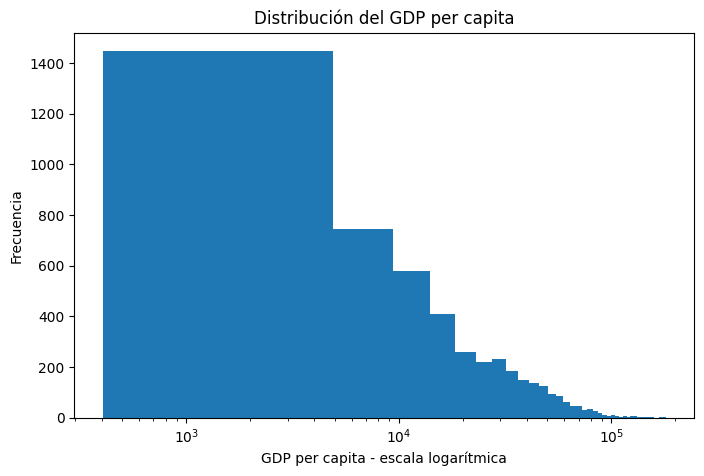

In [ ]:
# Distribución de GDP per capita
plt.figure(figsize=(8, 5))

plt.hist(df_eda_countries["gdp_per_capita"], bins=40)

plt.xscale("log")

plt.title("Distribución del GDP per capita")
plt.xlabel("GDP per capita - escala logarítmica")
plt.ylabel("Frecuencia")

plt.show()

### ► Interpretación de la distribución de `gdp_per_capita`

- La mayoría de los registros se concentra en niveles bajos y medios de GDP per capita.

- También se observa una cola hacia la derecha, causada por países/economías con valores muy altos de GDP per capita.

- Esto confirma que la variable tiene alta dispersión y valores extremos.

- En este gráfico se usa escala logarítmica en el eje X para visualizar mejor la distribución.

- Más adelante, si se usa esta variable en modelos de Machine Learning, se puede crear una variable transformada como `log_gdp_per_capita`.

## 3 Distribución de life_expectancy.
- Esta variable será la posible variable objetivo del modelo, por eso necesitamos entender su rango y concentración.


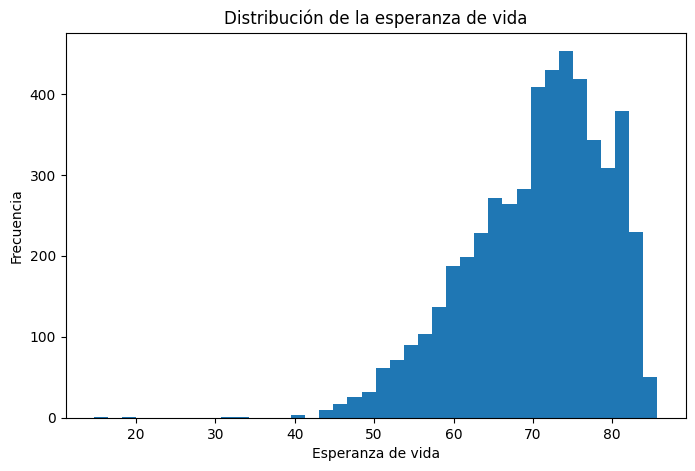

In [ ]:
# Distribución de life_expectancy
plt.figure(figsize=(8, 5))

plt.hist(df_eda_countries["life_expectancy"], bins=40)

plt.title("Distribución de la esperanza de vida")
plt.xlabel("Esperanza de vida")
plt.ylabel("Frecuencia")

plt.show()

### ►Interpretación de la distribución de life_expectancy

- La esperanza de vida se concentra entre los 60 y 85 años.

- - La distribución muestra pocos casos con esperanza de vida muy baja.
La mayor parte de los registros está alrededor de valores medios-altos, especialmente entre 70 y 80 años.

- Esto indica que, en general, la variable tiene menor dispersión que `gdp_per_capita`.

- Los casos que se van a la izquierda, por debajo de 40 años, son casos que deben revisarse porque pueden corresponder a países con crisis, conflictos, problemas sanitarios fuertes o años específicos con datos atípicos.


**Qué se hará con esta variable**
> - Se mantendrá como variable principal .
> - Se usará como posible variable objetivo del modelo de Machine Learning.
> - Se revisarán los valores muy bajos para entender si son casos reales o posibles outliers.
> - No requiere transformación logarítmica porque su escala es interpretable en años.

## 4 Distribución de population.

- Revisamos cómo se distribuye la población entre países.

- Esta variable suele tener valores extremos porque hay países muy pequeños y países muy poblados.

- Por eso usamos escala logarítmica en el eje X.

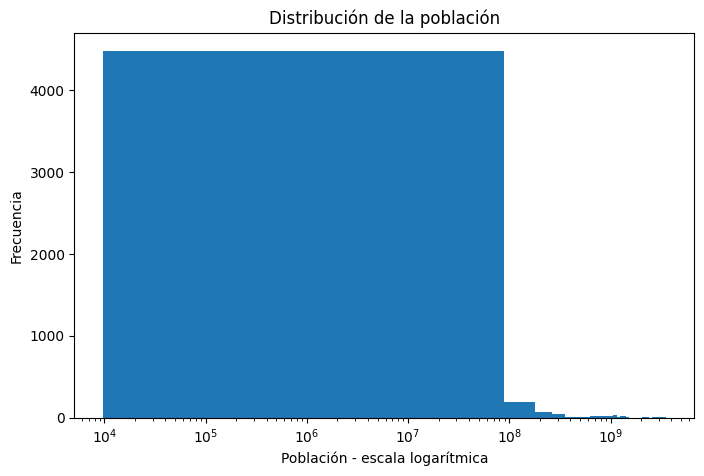

In [ ]:
# Distribución de population

plt.figure(figsize=(8, 5))

plt.hist(df_eda_countries["population"], bins=40)

plt.xscale("log")

plt.title("Distribución de la población")
plt.xlabel("Población - escala logarítmica")
plt.ylabel("Frecuencia")

plt.show()

### ► Interpretación de la distribución de `population`

- La población tiene una distribución muy desigual.Se observa una fuerte concentración hacia la izquierda y pocos casos con poblaciones muy altas.

- La mayoría de los registros corresponde a países/economías con poblaciones relativamente bajas o medias.

- La variable presenta alta dispersión debido a países muy poblados como China o India.

- En este gráfico se usa escala logarítmica en el eje X para visualizar mejor las diferencias entre países con tamaños poblacionales muy distintos.


**Qué se hará con esta variable**
> - Se mantendrá como variable de contexto.
> - Se usará con cuidado en gráficos y modelos por sus valores extremos.
> - Para visualizaciones, se puede usar escala logarítmica.
> - Para Machine Learning, probablemente convenga crear una variable transformada como log_population.

## 5 Relación entre gdp_per_capita y life_expectancy

Este gráfico evalúa la relación central del proyecto:
- *Ver si los países con mayor GDP per capita tienden a mostrar mayor esperanza de vida*.

Se usa escala logarítmica en `gdp_per_capita` porque la variable tiene valores extremos.

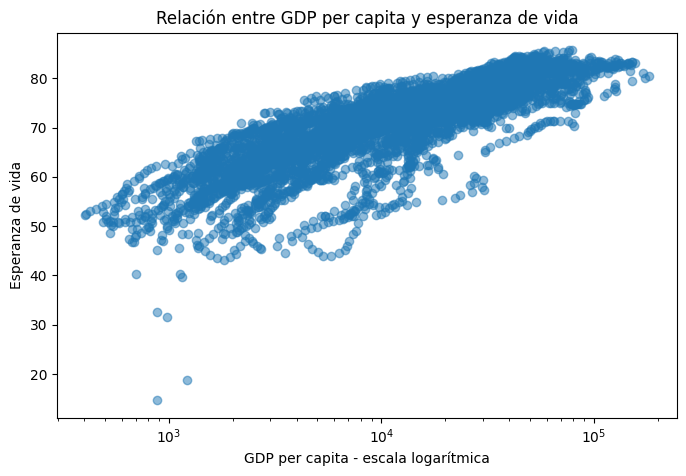

In [ ]:
# Relación entre GDP per capita y esperanza de vida
plt.figure(figsize=(8, 5))

plt.scatter(
    df_eda_countries["gdp_per_capita"],
    df_eda_countries["life_expectancy"],
    alpha=0.5
)

plt.xscale("log")

plt.title("Relación entre GDP per capita y esperanza de vida")
plt.xlabel("GDP per capita - escala logarítmica")
plt.ylabel("Esperanza de vida")

plt.show()

#### ► Interpretación de la relación entre `gdp_per_capita` y `life_expectancy`

- Se observa una relación positiva: a mayor GDP per capita, mayor esperanza de vida.

- La relación parece más fuerte en niveles bajos y medios de GDP per capita.

- En niveles altos de GDP per capita, la esperanza de vida tiende a estabilizarse.

- La relación no es lineal perfecta. El aumento del GDP per capita se relaciona con una mayor esperanza de vida, pero el efecto parece reducirse en países/economías con niveles económicos más altos.

- Esto sugiere que el crecimiento económico se asocia con mejores condiciones de vida, pero no explica todo por sí solo.

- También se observan casos atípicos que deberán revisarse más adelante.

## 6 Identificar casos particulares

- En este paso buscamos países que se salen del patrón general.

- El objetivo es encontrar casos útiles para generar insights.

Se revisarán países con:
> - GDP alto y esperanza de vida relativamente baja.
> - GDP medio y esperanza de vida alta.
> - GDP bajo y esperanza de vida alta.
> - poblaciones muy grandes.

Para evitar mezclar muchos años, se usará el año más reciente disponible en el dataset limpio.

In [ ]:
# Identificar casos particulares usando el año más reciente disponible
latest_year = df_eda_countries["year"].max()

df_latest = df_eda_countries[
    df_eda_countries["year"] == latest_year
].copy()

print("Año usado:", latest_year)
print("Filas disponibles:", df_latest.shape[0])

# Cuartiles de GDP per capita
q25_gdp = df_latest["gdp_per_capita"].quantile(0.25)
q75_gdp = df_latest["gdp_per_capita"].quantile(0.75)

# 1. GDP alto con esperanza de vida relativamente baja
high_gdp_low_life = df_latest[
    df_latest["gdp_per_capita"] >= q75_gdp
].sort_values("life_expectancy").head(10)

# 2. GDP medio con esperanza de vida alta
mid_gdp_high_life = df_latest[
    (df_latest["gdp_per_capita"] >= q25_gdp) &
    (df_latest["gdp_per_capita"] <= q75_gdp)
].sort_values("life_expectancy", ascending=False).head(10)

# 3. GDP bajo con esperanza de vida alta
low_gdp_high_life = df_latest[
    df_latest["gdp_per_capita"] <= q25_gdp
].sort_values("life_expectancy", ascending=False).head(10)

# 4. Países más poblados
most_populated = df_latest.sort_values("population", ascending=False).head(10)

print("\nGDP alto con esperanza de vida relativamente baja")
display(high_gdp_low_life[["country_name", "gdp_per_capita", "life_expectancy", "population"]])

print("\nGDP medio con esperanza de vida alta")
display(mid_gdp_high_life[["country_name", "gdp_per_capita", "life_expectancy", "population"]])

print("\nGDP bajo con esperanza de vida alta")
display(low_gdp_high_life[["country_name", "gdp_per_capita", "life_expectancy", "population"]])

print("\nPaíses más poblados")
display(most_populated[["country_name", "gdp_per_capita", "life_expectancy", "population"]])

Año usado: 2024
Filas disponibles: 199

GDP alto con esperanza de vida relativamente baja


,country_name,gdp_per_capita,life_expectancy,population
6532,Guyana,80155.039393,70.319000,831087.0
2110,Brunei Darussalam,89879.361498,75.501000,462721.0
856,Aruba,50649.301523,76.500000,107995.0
14122,Sint Maarten (Dutch part),53768.657395,76.528000,43350.0
9436,Lithuania,55285.899193,77.195122,2888278.0
12934,Poland,51262.510576,78.409756,36559233.0
16762,United States,85809.900385,78.890244,340110988.0
3562,Croatia,49550.792151,78.929268,3866200.0
13726,Saudi Arabia,71375.372789,78.982000,35300280.0
11878,North America,83521.838580,79.239140,381464223.0



GDP medio con esperanza de vida alta


,country_name,gdp_per_capita,life_expectancy,population
6070,Greece,44327.209781,81.839024,10405134.0
3034,Chile,36181.156617,81.359000,19764771.0
10030,Maldives,26182.783157,81.285000,527799.0
3430,Costa Rica,31106.764356,80.996000,5129910.0
12274,Oman,41740.165853,80.246000,5281538.0
262,Albania,26701.674956,79.776000,2377128.0
12604,Panama,41369.422541,79.775000,4515577.0
14188,Slovak Republic,48132.356431,78.370732,5422069.0
790,Armenia,22823.179526,78.319512,3033500.0
16894,Uruguay,36417.874162,78.287000,3386588.0



GDP bajo con esperanza de vida alta


,country_name,gdp_per_capita,life_expectancy,population
6796,Honduras,7486.018696,73.044,10825703.0
15706,Tajikistan,5405.980116,71.927,10590927.0
17026,Vanuatu,3605.607367,71.654,327777.0
14386,Solomon Islands,2674.893113,70.694,819198.0
11416,Nepal,5736.621343,70.636,29651054.0
13660,Sao Tome and Principe,6241.856145,69.905,235536.0
17290,West Bank and Gaza,4371.111359,69.213,5289152.0
13792,Senegal,5070.648621,68.924,18501984.0
10294,Mauritania,7368.752753,68.713,5169395.0
16498,Uganda,3273.267174,68.487,50015092.0



Países más poblados


,country_name,gdp_per_capita,life_expectancy,population
4156,Early-demographic dividend,13995.405558,72.008031,3.552279e+09
8710,Late-demographic dividend,28317.791254,77.233314,2.328628e+09
7390,India,11159.985648,72.235000,1.450936e+09
3100,China,27104.870268,78.017000,1.408975e+09
9040,Least developed countries: UN classification,4463.995642,66.705522,1.187778e+09
13066,Post-demographic dividend,68080.596537,81.112208,1.128378e+09
13132,Pre-demographic dividend,5268.749249,62.354327,1.105952e+09
5476,Fragile and conflict affected situations,6394.565913,63.604841,1.081768e+09
6664,Heavily indebted poor countries (HIPC),3611.762588,64.918060,9.414130e+08
11878,North America,83521.838580,79.239140,3.814642e+08


### ► Interpretación de casos destacados

- Se usó el año `2024`, con `199` filas  para el análisis.
- El objetivo fue identificar países que no siguen completamente la relación general entre `gdp_per_capita` y `life_expectancy`.

### En los casos de **GDP alto con esperanza de vida relativamente baja**,
 > - aparecen países/economías como Guyana, Brunei Darussalam, Aruba, Sint Maarten y Estados Unidos.  
 > - Esto muestra que un GDP per capita alto no siempre implica una esperanza de vida proporcionalmente alta.

### En los casos de **GDP medio con esperanza de vida alta**
 > - Aparecen países como Greece, Chile, Maldives, Costa Rica y Oman.  
 > - Esto refuerza la idea de que existen países con niveles económicos intermedios que logran buenos resultados en esperanza de vida.

### En los casos de **GDP bajo con esperanza de vida relativamente alta**
 > - Aparecen países como Honduras, Tajikistan, Vanuatu, Nepal y Senegal.  
 > - Estos casos sugieren que otros factores además del ingreso pueden influir en la esperanza de vida.

### En la tabla de países más poblados todavía aparecen agregados como
> - `Early-demographic dividend`
> - `Late-demographic dividend`
> - `Least developed countries: UN classification`
> - `Post-demographic dividend`
> - `Pre-demographic dividend`
> - `Fragile and conflict affected situations`
> - `North America`

#### Decisión

- Los resultados son útiles, pero todavía son preliminares.

- Antes de usar estos casos como conclusiones finales, se debe mejorar el filtro de agregados.

#### Próximo ajuste

- Antes de continuar con el modelo de Machine Learning, conviene ampliar la lista de agregados excluidos para que el dataset represente mejor países/economías individuales. Es decir, se creará una versión más limpia del dataset y se repetirá el análisis de casos interesantes.

## 8 Ajuste detectado durante la visualización
- Durante la revisión visual de los casos destacados se detectó que todavía quedaban registros que no representan países individuales.

- Estos registros pueden distorsionar rankings y gráficos, especialmente en visualizaciones relacionadas con población.

- Antes de continuar con las visualizaciones finales, se amplía la lista de agregados excluidos y se crea una versión más limpia del dataset.

- Esta corrección permite que los gráficos representen mejor países/economías individuales y no grupos agregados.

In [ ]:
# Agregados adicionales detectados durante la visualización
extra_aggregates_to_exclude = [
    "Early-demographic dividend",
    "Late-demographic dividend",
    "Least developed countries: UN classification",
    "Post-demographic dividend",
    "Pre-demographic dividend",
    "Fragile and conflict affected situations",
    "Heavily indebted poor countries (HIPC)",
    "North America"
]

# Ampliar lista de exclusión
aggregates_to_exclude_extended = aggregates_to_exclude + extra_aggregates_to_exclude

# Crear versión ajustada del dataset para visualización
df_viz_countries_clean = df_eda_main[
    ~df_eda_main["country_name"].isin(aggregates_to_exclude_extended)
].copy()

print("Antes:", df_eda_countries.shape)
print("Después:", df_viz_countries_clean.shape)

print("\nCountry names únicos:", df_viz_countries_clean["country_name"].nunique())
print("Country codes únicos:", df_viz_countries_clean["country_code"].nunique())

Antes: (5008, 6)
Después: (4816, 6)

Country names únicos: 206
Country codes únicos: 206


In [ ]:
# Dataset para visualización del año seleccionado

year_used = 2024

df_cases = df_viz_countries_clean[
    df_viz_countries_clean["year"] == year_used
].copy()

print("Año usado:", year_used)
print("Filas disponibles:", df_cases.shape[0])

Año usado: 2024
Filas disponibles: 191


In [ ]:
# Países/economías más pobladas después del ajuste

most_populated = df_cases.sort_values("population", ascending=False)

most_populated[
    ["country_name", "gdp_per_capita", "life_expectancy", "population"]
].head(10)

,country_name,gdp_per_capita,life_expectancy,population
7390,India,11159.985648,72.235000,1.450936e+09
3100,China,27104.870268,78.017000,1.408975e+09
16762,United States,85809.900385,78.890244,3.401110e+08
7456,Indonesia,16448.275518,71.288000,2.834879e+08
12472,Pakistan,6252.115432,67.799000,2.512692e+08
11812,Nigeria,9086.875506,54.635000,2.326795e+08
1978,Brazil,22338.476564,76.023000,2.119986e+08
1252,Bangladesh,9646.769844,74.930000,1.735624e+08
13396,Russian Federation,47404.964844,73.440488,1.435339e+08
4882,Ethiopia,3287.534922,67.603000,1.320598e+08


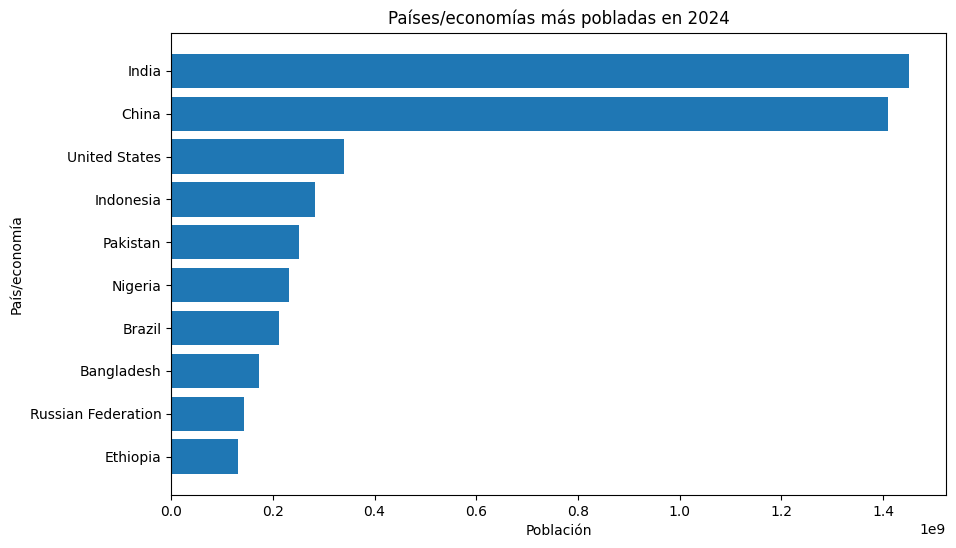

In [ ]:
# Visualización: países/economías más pobladas en 2024

year_used = 2024

df_cases = df_viz_countries_clean[
    df_viz_countries_clean["year"] == year_used
].copy()

top_population = (
    df_cases
    .sort_values("population", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_population["country_name"],
    top_population["population"]
)

plt.gca().invert_yaxis()

plt.title("Países/economías más pobladas en 2024")
plt.xlabel("Población")
plt.ylabel("País/economía")

plt.show()

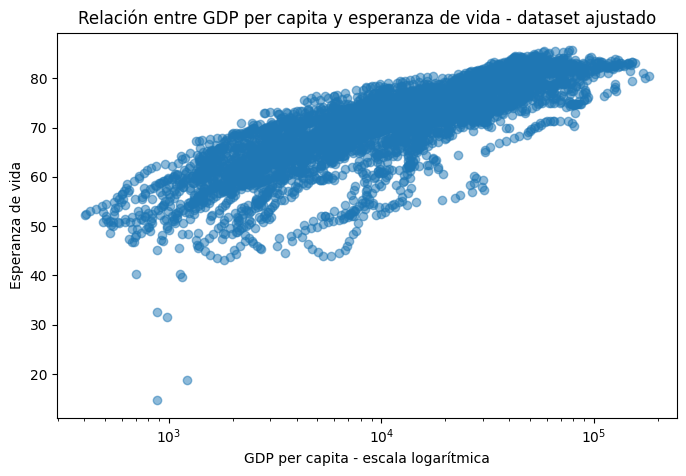

In [ ]:
# Relación entre GDP per capita y esperanza de vida después del ajuste

plt.figure(figsize=(8, 5))

plt.scatter(
    df_viz_countries_clean["gdp_per_capita"],
    df_viz_countries_clean["life_expectancy"],
    alpha=0.5
)

plt.xscale("log")

plt.title("Relación entre GDP per capita y esperanza de vida - dataset ajustado")
plt.xlabel("GDP per capita - escala logarítmica")
plt.ylabel("Esperanza de vida")

plt.show()

### ► Comparación después del ajuste del dataset

- Al comparar el gráfico original con el gráfico generado después de ampliar el filtro de agregados, no se observan cambios visuales importantes en la relación entre `gdp_per_capita` y `life_expectancy`.

- Esto indica que los agregados eliminados no modificaban de forma significativa el patrón principal del gráfico.

La relación general se mantiene:

- A mayor `gdp_per_capita`, mayor esperanza de vida.
- La relación no es perfectamente lineal.
- En niveles altos de GDP per capita, la esperanza de vida tiende a estabilizarse.

El ajuste del dataset fue útil como control de calidad, porque permitió eliminar registros que no representaban países/economías individuales, aunque la conclusión visual principal se mantuvo estable.

## 9 Definir variables para Machine Learning

- En este paso se define una primera estructura para el  modelo de Machine Learning.

El objetivo del modelo será predecir:

- `life_expectancy`

Las variables predictoras iniciales serán:

- `gdp_per_capita`
- `population`
- `year`

Como `gdp_per_capita` y `population` tienen valores extremos, se crearán versiones logarítmicas:

- `log_gdp_per_capita`
- `log_population`

Estas variables pueden ayudar a reducir el efecto de valores muy grandes en el modelo.

Este paso no entrena el modelo todavía. Solo prepara un dataset candidato para Machine Learning.

In [ ]:
# Definir variables candidatas para Machine Learning
df_ml_candidate = df_eda_countries.copy()

# Crear variables transformadas para reducir el efecto de valores extremos
df_ml_candidate["log_gdp_per_capita"] = np.log1p(df_ml_candidate["gdp_per_capita"])
df_ml_candidate["log_population"] = np.log1p(df_ml_candidate["population"])

# Definir variable objetivo
target = "life_expectancy"

# Definir variables predictoras iniciales
features = [
    "log_gdp_per_capita",
    "log_population",
    "year"
]

# Crear dataset candidato para ML
df_ml_candidate = df_ml_candidate[
    [
        "country_name",
        "country_code",
        "year",
        "gdp_per_capita",
        "population",
        "log_gdp_per_capita",
        "log_population",
        target
    ]
].dropna()

print("Dataset candidato para ML:", df_ml_candidate.shape)
print("Target:", target)
print("Features:", features)

df_ml_candidate.head()

Dataset candidato para ML: (5008, 8)
Target: life_expectancy
Features: ['log_gdp_per_capita', 'log_population', 'year']


,country_name,country_code,year,gdp_per_capita,population,log_gdp_per_capita,log_population,life_expectancy
41,Afghanistan,AFG,2001,747.688045,20284307.0,6.618322,16.825358,55.511
42,Afghanistan,AFG,2002,926.507941,21378117.0,6.832501,16.877878,56.225
43,Afghanistan,AFG,2003,966.962032,22733049.0,6.875193,16.939330,57.171
44,Afghanistan,AFG,2004,971.633503,23560654.0,6.880007,16.975089,57.810
45,Afghanistan,AFG,2005,1076.087353,24404567.0,6.982016,17.010281,58.247


### ► Resultado de definición de variables para Machine Learning

Se creó el dataset candidato para Machine Learning:

- Filas: `5,008`
- Columnas: `8`
- Target: `life_expectancy`
- Features iniciales:
  - `log_gdp_per_capita`
  - `log_population`
  - `year`

Se usaron versiones logarítmicas de `gdp_per_capita` y `population` porque ambas variables tienen valores extremos.

El dataset no tiene valores faltantes en las variables seleccionadas, por lo que puede usarse como base inicial para un modelo de regresión.

#### Decisión

El primer modelo buscará predecir la esperanza de vida de un país en un año determinado usando:

- nivel económico;
- tamaño poblacional;
- año.

Este modelo será simple, pero sirve como primera línea base para evaluar si las variables disponibles tienen capacidad predictiva.

# Parte IV: Machine Learning

Este parte trata un problema de **regresión**, porque la variable objetivo es `life_expectancy`, una variable numérica.

El objetivo del modelo es predecir la esperanza de vida de un país en un año determinado utilizando variables como el nivel económico, la población y el año.

Se utilizan modelos de regresión como `Linear Regression` y `Random Forest Regressor`.

La variable objetivo del modelo es:

- `life_expectancy`

Las variables predictoras utilizadas son:

- `log_gdp_per_capita`
- `log_population`
- `year`

## 1 Revisar agregados en el dataset para ML

Antes de entrenar el modelo, se revisa si quedan registros agregados en `df_ml_candidate`.

Ejemplos detectados durante la revisión:

- `World`
- `North America`
- `Early-demographic dividend`
- `Late-demographic dividend`
- `Least developed countries: UN classification`
- `Post-demographic dividend`
- `Pre-demographic dividend`
- `Fragile and conflict affected situations`
- `Heavily indebted poor countries (HIPC)`

Estos registros pueden distorsionar el modelo porque mezclan países/economías individuales con regiones, grupos demográficos o clasificaciones internacionales.

El modelo debería aprender patrones entre países/economías individuales, no entre agregados.

In [ ]:
# Revisar posibles agregados restantes en el dataset candidato para ML

aggregate_keywords = [
    "World",
    "income",
    "dividend",
    "classification",
    "situations",
    "North America",
    "Europe",
    "European Union",
    "Euro area",
    "Asia",
    "Africa",
    "Arab World",
    "OECD",
    "IDA",
    "IBRD",
    "countries",
    "total",
    "Latin America",
    "Caribbean",
    "Pacific",
    "Middle East",
    "Sub-Saharan",
    "Central Asia",
    "Baltics",
    "small states",
    "Least developed",
    "Fragile",
    "Heavily indebted",
    "HIPC",
    "demographic"
]

pattern = "|".join(aggregate_keywords)

possible_ml_aggregates = df_ml_candidate[
    df_ml_candidate["country_name"].str.contains(
        pattern,
        case=False,
        na=False
    )
]["country_name"].drop_duplicates().sort_values()

possible_ml_aggregates.tolist()

['Central African Republic',
 'Early-demographic dividend',
 'Fragile and conflict affected situations',
 'Heavily indebted poor countries (HIPC)',
 'Late-demographic dividend',
 'Least developed countries: UN classification',
 'North America',
 'Other small states',
 'Pacific island small states',
 'Post-demographic dividend',
 'Pre-demographic dividend',
 'Small states',
 'South Africa',
 'Trinidad and Tobago']

### ► Resultado de la revisión de agregados restantes

La revisión encontró registros que todavía podían confundirse con países/economías individuales.

#### Agregados que sí deben eliminarse

Estos registros representan grupos, clasificaciones o regiones agregadas, no países/economías individuales:

- `Early-demographic dividend`
- `Late-demographic dividend`
- `Least developed countries: UN classification`
- `Post-demographic dividend`
- `Pre-demographic dividend`
- `Fragile and conflict affected situations`
- `Heavily indebted poor countries (HIPC)`
- `North America`

#### Registros que no deben eliminarse

También aparecieron nombres que contienen palabras como `Africa`, pero que sí corresponden a países individuales:

- `Central African Republic`
- `South Africa`
- `Trinidad and Tobago`

#### Decisión

- Se eliminarán únicamente los agregados claros.  
- Los países/economías individuales se mantienen, aunque su nombre contenga palabras similares a las usadas en la búsqueda.

## 2 Eliminar agregados restantes del dataset candidato para ML


In [ ]:
# Eliminar agregados restantes del dataset candidato para ML
ml_aggregates_to_exclude = [
    "Early-demographic dividend",
    "Late-demographic dividend",
    "Least developed countries: UN classification",
    "Post-demographic dividend",
    "Pre-demographic dividend",
    "Fragile and conflict affected situations",
    "Heavily indebted poor countries (HIPC)",
    "North America"
]

df_ml = df_ml_candidate[
    ~df_ml_candidate["country_name"].isin(ml_aggregates_to_exclude)
].copy()

print("Antes:", df_ml_candidate.shape)
print("Después:", df_ml.shape)
print("Country names únicos:", df_ml["country_name"].nunique())
print("Country codes únicos:", df_ml["country_code"].nunique())

df_ml.head()

Antes: (5008, 8)
Después: (4816, 8)
Country names únicos: 206
Country codes únicos: 206


,country_name,country_code,year,gdp_per_capita,population,log_gdp_per_capita,log_population,life_expectancy
41,Afghanistan,AFG,2001,747.688045,20284307.0,6.618322,16.825358,55.511
42,Afghanistan,AFG,2002,926.507941,21378117.0,6.832501,16.877878,56.225
43,Afghanistan,AFG,2003,966.962032,22733049.0,6.875193,16.939330,57.171
44,Afghanistan,AFG,2004,971.633503,23560654.0,6.880007,16.975089,57.810
45,Afghanistan,AFG,2005,1076.087353,24404567.0,6.982016,17.010281,58.247


#### ► Resultado de limpieza de agregados para ML

Se eliminaron los agregados restantes del dataset candidato para Machine Learning.

Antes de la limpieza:

- `5,008` filas
- `8` columnas

Después de la limpieza:

- `4,816` filas
- `8` columnas
- `206` nombres únicos en `country_name`
- `206` códigos únicos en `country_code`

Se eliminaron registros agregados como:

- `Early-demographic dividend`
- `Late-demographic dividend`
- `North America`
- `Least developed countries: UN classification`
- `Fragile and conflict affected situations`
- `Heavily indebted poor countries (HIPC)`

Los países/economías individuales se mantuvieron.

#### Interpretación

- El dataset `df_ml` queda más adecuado para Machine Learning porque reduce la mezcla entre países/economías individuales y registros agregados, como regiones, grupos demográficos o clasificaciones internacionales.

- La reducción de `5,008` a `4,816` filas indica que se eliminaron observaciones asociadas a esos agregados a través de distintos años.

- Este dataset será la base para entrenar el modelo.

#### Próximo paso

Separar las variables del modelo:

- `X`: variables predictoras.
- `y`: variable objetivo.

In [ ]:
# Verificamos que North America no sea USA con un dataset anterior\
df_ml_candidate[
    df_ml_candidate["country_name"].isin(["North America", "United States"])
][["country_name", "country_code"]].drop_duplicates()

,country_name,country_code
11855,North America,NAC
16739,United States,USA


## 3 Separar variables del modelo

En este paso separamos el dataset en:

> - X: variables predictoras.
> - y: variable objetivo.

El modelo intentará predecir life_expectancy.

Usaremos como variables predictoras:

log_gdp_per_capita
log_population
year

In [ ]:
# Separar variables predictoras y variable objetivo
features = [
    "log_gdp_per_capita",
    "log_population",
    "year"
]

target = "life_expectancy"

X = df_ml[features]
y = df_ml[target]

print("X:", X.shape)
print("y:", y.shape)

X.head()

X: (4816, 3)
y: (4816,)


,log_gdp_per_capita,log_population,year
41,6.618322,16.825358,2001
42,6.832501,16.877878,2002
43,6.875193,16.939330,2003
44,6.880007,16.975089,2004
45,6.982016,17.010281,2005


#### ► Resultado de separación de variables

Se separaron las variables del modelo:

- `X`: variables predictoras.
- `y`: variable objetivo.

El conjunto `X` tiene:

- `4,816` filas
- `3` variables predictoras

Variables predictoras:

- `log_gdp_per_capita`
- `log_population`
- `year`

El conjunto `y` tiene:

- `4,816` valores

Variable objetivo:

- `life_expectancy`

Esto confirma que el dataset está listo para dividirse en entrenamiento y prueba.

## 4 Dividir datos en entrenamiento y prueba

En este paso dividimos los datos en dos partes:

- entrenamiento: para que el modelo aprenda;
- prueba: para evaluar qué tan bien predice con datos que no vio antes.

Usaremos 80% para entrenamiento y 20% para prueba

In [ ]:
# Dividir datos en entrenamiento y prueba
# from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3852, 3)
X_test: (964, 3)
y_train: (3852,)
y_test: (964,)


#### ► Resultado de división de datos

Los datos se dividieron en entrenamiento y prueba.

| Conjunto | Filas |
|---|---:|
| `X_train` | 3,852 |
| `X_test` | 964 |
| `y_train` | 3,852 |
| `y_test` | 964 |

El modelo entrenará con `3,852` registros y se evaluará con `964` registros que no usó durante el entrenamiento.

Esto permite medir si el modelo generaliza o si solo memoriza los datos de entrenamiento.

## 5 Entrenar modelo base: Linear Regression

En este paso entrenamos un primer modelo simple.

Linear Regression sirve como línea base para evaluar si las variables seleccionadas tienen capacidad inicial para predecir life_expectancy.

In [ ]:
# Entrenar modelo base con Linear Regression
# from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Modelo entrenado correctamente")

Modelo entrenado correctamente


### ► Resultado del entrenamiento

El modelo base `Linear Regression` fue entrenado correctamente.

Este modelo aprendió una relación inicial entre las variables predictoras:

- `log_gdp_per_capita`
- `log_population`
- `year`

y la variable objetivo:

- `life_expectancy`

El siguiente paso es usar el modelo para predecir sobre `X_test` y evaluar su desempeño.

## 6 Evaluar modelo base

En este paso usamos el modelo entrenado para predecir life_expectancy en el conjunto de prueba.

Luego calculamos tres métricas:

MAE: error promedio en años.
RMSE: error promedio penalizando más los errores grandes.
R²: porcentaje de variación explicado por el modelo.

In [ ]:
# Evaluar modelo base
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_linear = linear_model.predict(X_test)

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("MAE:", mae_linear)
print("RMSE:", rmse_linear)
print("R²:", r2_linear)

MAE: 3.5162748302338733
RMSE: 4.741070910677824
R²: 0.6920157641722737


### ► Resultado de evaluación del modelo base

El modelo `Linear Regression` obtuvo estos resultados:

| Métrica | Resultado | Interpretación |
|---|---:|---|
| `MAE` | 3.52 | El modelo se equivoca, en promedio, por 3.52 años de esperanza de vida. |
| `RMSE` | 4.74 | El error aumenta cuando hay predicciones muy alejadas del valor real. |
| `R²` | 0.69 | El modelo explica aproximadamente el 69% de la variación en la esperanza de vida. |

#### Interpretación

El modelo base tiene un desempeño aceptable para una primera aproximación.

Con solo tres variables:

- `log_gdp_per_capita`
- `log_population`
- `year`

el modelo logra capturar una parte importante de la relación con `life_expectancy`.

Sin embargo, todavía hay margen de mejora. El error promedio de 3.52 años indica que faltan variables relevantes para explicar mejor la esperanza de vida.

#### Próximo paso

Entrenar un modelo más flexible, como `Random Forest Regressor`, para comparar si mejora el desempeño.

## 7 Validación cruzada del modelo base

- En este paso aplicamos validación cruzada al modelo `Linear Regression`.

- La validación cruzada permite evaluar el modelo en varias divisiones diferentes del dataset, no solo en una única división de entrenamiento y prueba.

Esto ayuda a obtener una mejor evaluación del desempeño.

In [ ]:
# Validación cruzada del modelo Linear Regression
# from sklearn.model_selection import cross_validate

cv_linear = cross_validate(
    linear_model,
    X,
    y,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    }
)

mae_cv_linear = -cv_linear["test_mae"].mean()
rmse_cv_linear = -cv_linear["test_rmse"].mean()
r2_cv_linear = cv_linear["test_r2"].mean()

print("Validación cruzada - Linear Regression")
print("MAE promedio:", mae_cv_linear)
print("RMSE promedio:", rmse_cv_linear)
print("R² promedio:", r2_cv_linear)

Validación cruzada - Linear Regression
MAE promedio: 3.5491918349810674
RMSE promedio: 4.815570694911116
R² promedio: 0.6864128386070723


### ► Interpretación de la validación cruzada del modelo base

- La validación cruzada de `Linear Regression` muestra un desempeño promedio aceptable.

- El modelo obtuvo un **MAE promedio de 3.55**, lo que significa que, en promedio, sus predicciones se alejan aproximadamente **3.5 años** del valor real de esperanza de vida.

- El **RMSE promedio fue de 4.82**, lo que indica que algunos errores son más altos.

- El **R² promedio fue de 0.69**, por lo que el modelo logra explicar aproximadamente el **69% de la variabilidad** de la esperanza de vida.

En general, el modelo base tiene una capacidad predictiva razonable, pero todavía puede mejorarse utilizando modelos más flexibles como `Random Forest`.

## 8 Entrenar modelo Random Forest

- Crea el modelo Random Forest
- lo entrena con X_train y y_train
- aprende patrones de los datos de entrenamiento

Con este modelo
- Se puede capturar relaciones no lineales entre las variables predictoras y `life_expectancy`.
- Sirve para comparar si mejora el desempeño frente a Linear Regression.

In [ ]:
# Entrenar modelo Random Forest Regressor
# from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Modelo Random Forest entrenado correctamente")

Modelo Random Forest entrenado correctamente


### ► Resultado del entrenamiento

- El modelo `Random Forest Regressor` fue entrenado correctamente.

- El siguiente paso es evaluar su desempeño usando el conjunto de prueba.

### Usar Random Forest ya entrenado
- predice valores sobre X_test
- compara las predicciones contra y_test
- calcula métricas de error y desempeño

In [ ]:
# Evaluar modelo Random Forest

y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R²:", r2_rf)

MAE: 1.951478281872259
RMSE: 3.0821178035303753
R²: 0.869841044732033


### ► Resultado de evaluación del modelo Random Forest

El modelo `Random Forest Regressor` obtuvo estos resultados:

| Métrica | Resultado | Interpretación |
|---|---:|---|
| `MAE` | 1.95 | El modelo se equivoca, en promedio, por 1.95 años de esperanza de vida. |
| `RMSE` | 3.08 | Los errores grandes son menores que en el modelo lineal. |
| `R²` | 0.87 | El modelo explica aproximadamente el 87% de la variación en la esperanza de vida. |

#### Interpretación

`Random Forest` mejora el desempeño frente a `Linear Regression`.

## 9 Validación cruzada del modelo Random Forest

- La validación cruzada de `Random Forest Regressor` permite evaluar el desempeño del modelo en distintas divisiones del dataset.

- Esto ayuda a comprobar si el resultado del modelo se mantiene de forma estable y no depende solamente de una única división entre datos de entrenamiento y prueba.

In [ ]:
# Validación cruzada del modelo Random Forest
# from sklearn.model_selection import cross_validate

cv_rf = cross_validate(
    rf_model,
    X,
    y,
    cv=5,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    }
)

mae_cv_rf = -cv_rf["test_mae"].mean()
rmse_cv_rf = -cv_rf["test_rmse"].mean()
r2_cv_rf = cv_rf["test_r2"].mean()

print("Validación cruzada - Random Forest")
print("MAE promedio:", mae_cv_rf)
print("RMSE promedio:", rmse_cv_rf)
print("R² promedio:", r2_cv_rf)

Validación cruzada - Random Forest
MAE promedio: 4.368877031160065
RMSE promedio: 5.929435111766611
R² promedio: 0.5254109079302189


### ► Interpretación de la validación cruzada del modelo Random Forest

- La validación cruzada del modelo `Random Forest Regressor` muestra un desempeño más bajo que el obtenido en la evaluación inicial con `train_test_split`.

- El modelo obtuvo un **MAE promedio de 4.37**, lo que significa que, en promedio, sus predicciones se alejan aproximadamente **4.4 años** del valor real de esperanza de vida.

- El **RMSE promedio fue de 5.93**, indicando que existen errores relativamente altos en algunas predicciones.

- El **R² promedio fue de 0.53**, por lo que el modelo explica aproximadamente el **53% de la variabilidad** de la esperanza de vida durante la validación cruzada.

Esto indica que el rendimiento del modelo no es tan estable cuando se evalúa en distintas particiones del dataset. Aunque Random Forest tuvo buen desempeño, la validación cruzada muestra que puede necesitar mejora de parámetros.

## 10 Optimización de hiperparámetros del modelo Random Forest

En este paso se aplica `RandomizedSearchCV` para buscar una mejor combinación de hiperparámetros del modelo `Random Forest Regressor`.

- La optimización permite probar distintas configuraciones del modelo y seleccionar la que obtiene mejor rendimiento en la validación cruzada.

- En este caso, se optimiza el modelo usando como criterio el menor error promedio medido con `RMSE`.

In [ ]:
# Optimización de hiperparámetros para Random Forest
# from sklearn.model_selection import RandomizedSearchCV
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

param_dist_rf = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", None]
}

rf_random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_dist_rf,
    n_iter=20,
    cv=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1
)

rf_random_search.fit(X_train, y_train)

print("Mejores hiperparámetros encontrados:")
print(rf_random_search.best_params_)

print("\nMejor RMSE promedio en validación cruzada:")
print(-rf_random_search.best_score_)

Mejores hiperparámetros encontrados:
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': None}

Mejor RMSE promedio en validación cruzada:
3.3680384286627287


In [ ]:
print(-rf_random_search.best_score_)

3.3680384286627287


### ► Interpretación de la optimización de hiperparámetros

La optimización de hiperparámetros encontró como mejor configuración un modelo `Random Forest Regressor` con:

> - `n_estimators = 500`
> - `max_depth = None`
> - `min_samples_split = 2`
> - `min_samples_leaf = 1`
> - `max_features = None`

- El mejor **RMSE promedio en validación cruzada fue de 3.37**.

Este resultado mejora  el desempeño obtenido por el Random Forest en validación cruzada, que tenía un **RMSE promedio de 5.93**.

También mejora el resultado del modelo base `Linear Regression`, con **RMSE promedio en validación cruzada fue de 4.82**.

Esto indica que la optimización de hiperparámetros permitió una configuración más precisa y estable para el modelo Random Forest.

## 11 Evaluación del modelo Random Forest optimizado

- En este paso se evalúa el mejor modelo encontrado por `RandomizedSearchCV`

- Esto permite comparar el rendimiento del modelo optimizado frente a los modelos anteriores.

In [ ]:
# Evaluar el modelo Random Forest optimizado
best_rf_model = rf_random_search.best_estimator_

y_pred_best_rf = best_rf_model.predict(X_test)

mae_best_rf = mean_absolute_error(y_test, y_pred_best_rf)
rmse_best_rf = np.sqrt(mean_squared_error(y_test, y_pred_best_rf))
r2_best_rf = r2_score(y_test, y_pred_best_rf)

print("Random Forest optimizado")
print("MAE:", mae_best_rf)
print("RMSE:", rmse_best_rf)
print("R²:", r2_best_rf)

Random Forest optimizado
MAE: 1.9250491720344458
RMSE: 3.0329361388587204
R²: 0.8739618216341889


### ► Interpretación del modelo Random Forest optimizado

El modelo `Random Forest Regressor` optimizado obtuvo un mejor desempeño que los modelos anteriores en el conjunto de prueba.

- El **MAE fue de 1.93**, lo que significa que, en promedio, las predicciones del modelo se alejan unos **1.9 años** del valor real de esperanza de vida.

- El **RMSE fue de 3.03**, lo que indica que el modelo mantiene un nivel de error relativamente bajo.

- El **R² fue de 0.87**, por lo que el modelo logra explicar aproximadamente el **87% de la variabilidad** de la esperanza de vida.

Estos resultados muestran que la optimización de hiperparámetros mejoró el rendimiento del modelo Random Forest y lo convierte, hasta este punto, en el modelo con mejor desempeño del proyecto.

---

## 12 Revisar importancia de variables del modelo optimizado

- En este paso revisamos qué variables tuvieron más peso en el modelo `Random Forest` optimizado.

- Esto ayuda a interpretar qué factores fueron más útiles para predecir `life_expectancy`.

In [ ]:
# Revisar importancia de variables en el Random Forest optimizado
feature_importance = pd.DataFrame({
    "feature": features,
    "importance": best_rf_model.feature_importances_
}).sort_values("importance", ascending=False)

feature_importance

,feature,importance
0,log_gdp_per_capita,0.758103
1,log_population,0.185661
2,year,0.056236


### ► Interpretación de la importancia de variables

- La variable más importante para el modelo `Random Forest` optimizado fue `log_gdp_per_capita`, con **75.8%**.

- Esto indica que el nivel económico del país fue el principal factor utilizado por el modelo para predecir la esperanza de vida.

- La segunda variable más importante fue `log_population`, con **18.6%**. Esto sugiere que el tamaño de la población también aporta información útil.

## 13 Comparar valores reales vs predicciones

- En este paso comparamos **la esperanza de vida real** con **la esperanza de vida predicha** por el modelo Random Forest.

- Si el modelo funciona bien, los puntos deberían acercarse a una línea diagonal.

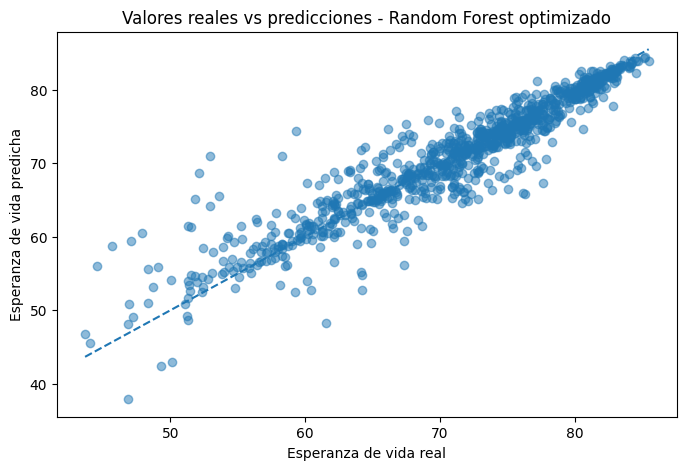

In [ ]:
# Comparar valores reales vs predicciones del modelo Random Forest optimizado
y_pred_best_rf = best_rf_model.predict(X_test)

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_best_rf, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Valores reales vs predicciones - Random Forest optimizado")
plt.xlabel("Esperanza de vida real")
plt.ylabel("Esperanza de vida predicha")

plt.show()

### ► Interpretación de valores reales vs predicciones

- Las predicciones quedan bastante cerca de la línea diagonal.

- Esto significa que el modelo `Random Forest` optimizado logra predecir valores similares a los valores reales de `life_expectancy`.

- La mayoría de los puntos se concentran entre 65 y 85 años.

- También se observan algunos errores más grandes en países con menor esperanza de vida, especialmente por debajo de 60 años.

- El gráfico parece mostrar que el modelo tiene un buen ajuste general.

## 14 Comparar modelos

- En este paso comparamos los resultados de los modelos entrenados.

- Se comparan tres modelos:

  - `Linear Regression`
  - `Random Forest`
  - `Random Forest optimizado`

- La comparación se hace usando MAE, RMSE y R2.

In [ ]:
# Comparar métricas de modelos
model_results = pd.DataFrame({
    "model": [
        "Linear Regression",
        "Random Forest",
        "Random Forest optimizado"
    ],
    "MAE": [
        mae_linear,
        mae_rf,
        mae_best_rf
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf,
        rmse_best_rf
    ],
    "R2": [
        r2_linear,
        r2_rf,
        r2_best_rf
    ]
})

model_results

,model,MAE,RMSE,R2
0,Linear Regression,3.516275,4.741071,0.692016
1,Random Forest,1.951478,3.082118,0.869841
2,Random Forest optimizado,1.925049,3.032936,0.873962


### ► Interpretación de comparación de modelos

- El modelo `Linear Regression` fue el modelo base.

- Tuvo un **MAE de 3.52**, un **RMSE de 4.74** y un **R² de 0.69**.

- El modelo `Random Forest` mejoró bastante el resultado, con un **MAE de 1.95**, un **RMSE de 3.08** y un **R² de 0.87**.

- Después de la optimización, el `Random Forest optimizado` tuvo el mejor resultado general.

- Fue el modelo con menor error:

  - MAE: **1.93**
  - RMSE: **3.03**

- También tuvo el mejor R2: **0.87**.

- Por eso, el modelo final seleccionado es `Random Forest optimizado`.

----

## **Conclusiones finales del proyecto**

- El análisis muestra que existe una relación positiva entre `gdp_per_capita` y `life_expectancy`.

- En general, los países con mayor GDP per capita tienden a tener mayor esperanza de vida.

- Pero, la relación no es perfecta, tener mayor nivel económico no garantiza automáticamente mejores condiciones de vida.

- En el análisis exploratorio se observó que la relación entre GDP per capita y esperanza de vida es más clara en niveles bajos y medios de ingreso. En niveles altos, la esperanza de vida tiende a estabilizarse.

- Desde Machine Learning, el proyecto se trabajó como un problema de regresión, porque la variable objetivo fue `life_expectancy`, una variable numérica continua.

- Se entrenaron y compararon tres modelos:

| Modelo | MAE | RMSE | R² |
|---|---:|---:|---:|
| Linear Regression | 3.52 | 4.74 | 0.69 |
| Random Forest | 1.95 | 3.08 | 0.87 |
| Random Forest optimizado | 1.93 | 3.03 | 0.87 |

- El modelo con mejor desempeño fue `Random Forest optimizado`.

- Este modelo obtuvo el menor error, con un MAE de **1.93** y un RMSE de **3.03**.

- La variable más importante del modelo fue `log_gdp_per_capita`, con **75.8%** de importancia.

- Esto confirma que el nivel económico fue el factor que más ayudó al modelo a predecir la esperanza de vida.

- Aun así, el GDP per capita no explica todo. El modelo también usó `log_population`, pero no incluye, por ahora, otras variables sociales importantes.

#### Limitación

- El modelo usa pocas variables predictoras.
- Para mejorar se podrían agregar variables como desigualdad, gasto en salud, escolarización, acceso a servicios básicos o calidad institucional.
- Aunque el curso también trabaja modelos de clasificación como SVM, este proyecto es un problema de regresión, porque la variable objetivo `life_expectancy` es numérica continua.

#### Conclusión principal

- El crecimiento económico está relacionado con mejores niveles de esperanza de vida, pero no garantiza por sí solo mejores condiciones de vida.

- Para entender mejor la calidad de vida de un país, es necesario analizar el GDP junto con otros factores sociales y demográficos.

# Temas del curso que no se incluyeron

- **SQL:** no lo usé en este proyecto, porque trabajé con archivos CSV del World Bank.
- **APIs:** en la primera entrega sí trabajé con datos de fuentes públicas, pero en esta versión cambié y usé los datos ya descargados en CSV.
- **SVM:** no lo incluí porque mi problema es de regresión.
- **Matriz de confusión / accuracy:** no las usé porque son métricas para clasificación. En este proyecto usé MAE, RMSE y R².
- **PCA / reducción de dimensionalidad:** no lo usé porque el modelo final tiene pocas variables predictoras.
- **K-means:** no lo usé porque el objetivo no era agrupar países.
- **GIS / análisis espacial:** no se enfocó en mapas.
- **XGBoost / SHAP:** no los usé. En esta entrega trabajé con `Linear Regression`, `Random Forest` y optimización con `RandomizedSearchCV`.

## Qué podría incluir en el futuro
- Podría volver a usar **APIs** para traer nuevas categorias.
- Podría usar **SQL** si guardo los datos en una base de datos y hago consultas por país, año o indicador.
- Podría agregar más variables, por ejemplo salud, educación, desigualdad, acceso a servicios básicos o gasto público.
- Si agrego más variables, podría probar **PCA** para reducir dimensiones.
- Podría usar **K-means** para agrupar paises.
- Podría usar **XGBoost** para mejorar el modelo.
- Podría usar **SHAP** para mejor predicciones.